# JBI030 - Graded Homework Assignment 2

This notebook explains and provides the setup code for JBI030 homework assignment 2.

In assignment 1, we considered regression tasks where the target was a number, such as the median house price of a California district.
This assignment covers two parts.

1. __Supervised Learning - Classification.__ In sections 1 to 3 the goal is to predict a class label, such as whether an applicant buys a house or which digit an image shows. These sections cover Naive Bayes, decision trees, and a neural network trained with gradient descent.
2. __Unsupervised Learning.__ The tasks in sections 4 to 6 have no target, and the result is a factorization of the data matrix into two smaller matrices. The three applications are filling in missing movie ratings, finding corrupted records, and grouping districts into regions. All three minimize the same objective under different constraints.

The rules are the same as in assignment 1. __Solve the exercises with Numpy__, not with AI or scikit-learn.
As discussed in assignment 1, working through the problems yourself builds understanding, and these exercises prepare you for the exam.
We provide the setup code.
You implement the core methods.

## Software libraries

We will use [Numpy](https://numpy.org/doc/) for algorithm implementation, [Pandas](https://pandas.pydata.org/docs/) for data analysis and [Matplotlib](https://matplotlib.org/stable/index.html) for data visualization.

## Datasets

You will keep working with the [California housing dataset](https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset) from assignment 1.
Three more datasets are shipped as files in the `data` directory. They are a movie rating matrix from [MovieLens](https://grouplens.org/datasets/movielens/) (F. M. Harper and J. A. Konstan, 2015. The MovieLens Datasets: History and Context. ACM TiiS 5, 4), a small two-dimensional toy dataset, and a subset of the [MNIST](https://en.wikipedia.org/wiki/MNIST_database) handwritten digits (LeCun, Cortes and Burges).

## Handing in the exercises

You will use ANS to hand in your answers. You should hand in the Jupyter notebook as well, named `GROUPNAME_assignment_2.ipynb` and the corresponding pdf, named `GROUPNAME_assignment_2.pdf`.

Please copy the whole answers, including all decimals.

In [1]:
# Imports for the exercises
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
from pathlib import Path
from typing import Callable
#from tqdm.auto import tqdm
from tqdm import tqdm

In [2]:
data_dir = Path("data/")

# The California housing dataset
features_table = pq.read_table(data_dir / "california_housing_features.parquet")
pandas_data = features_table.to_pandas()
pandas_target = pq.read_table(data_dir / "california_housing_target.parquet").to_pandas().squeeze("columns")

# Better styling for plotting
plt.style.use('seaborn-v0_8-whitegrid')

pandas_data.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [3]:
# The train and test split of assignment 1
row_index = np.arange(len(pandas_target))
is_test = row_index % 5 == 0
is_train = ~is_test

features_all = pandas_data.to_numpy()
target_all = pandas_target.to_numpy()

features_train_raw, features_test_raw = features_all[is_train], features_all[is_test]
price_train, price_test = target_all[is_train], target_all[is_test]

print(f"Train districts: {len(price_train)}, test districts: {len(price_test)}")

Train districts: 16512, test districts: 4128


# Part 1: Supervised Learning (Classification)

## 1. Classification with Naive Bayes

In assignment 1, every prediction was a number. You defined a model, defined a loss, and minimized the loss with gradient descent to produce a regression model.

In the first part of assignment 2 you will build multiple __classification models__. 
The prediction is a __class__, one of a fixed set of categories.

You can go about that in a number of ways.
In this exercise you will use Naive Bayes.
Contrary to the regression approach of the previous section you will not compute a loss nor a gradient. 
Instead you will work with probabilities calculated from the training data. 

|  | Regression | Classification w. Naive Bayes |
| --- | --- | --- |
| Prediction | a number $\hat{y}$ | a class |
| Parameters | weights $w$ | probability tables |
| How parameters are found | gradient descent on a loss | counting rows in the training data |
| Training cost | many update steps | one pass over the data |

### The idea

Imagine you joined __HomeWise__, a startup that helps mortgage officers qualify leads.

Hundreds of loan inquiries come in every week, far too many to call, and the product manager wants to flag the applicants that are likely to buy a house, using only the few features on the application form.

Bayes' rule can be used to determine such a probability, given the training data available to us.
For a class $y$ and an observed feature vector $\mathbf{x} = (x_1, \dots, x_d)$ it states
$$p(y \mid \mathbf{x}) = \frac{p(\mathbf{x} \mid y)\,p(y)}{p(\mathbf{x})}$$
In our example $y$ has two classes: "interested" and "not interested".
The features in feature vector $\mathbf{x}$ are the answers on the application form.

The probability that you observe a class $y$ given some observation or input vector $\mathbf{x}$ is denoted as the __posterior__ $p(y \mid \mathbf{x})$.
Here that means "the probability that an applicant is interested in buying a home, given the filled out application form".
This is what we currently would like to know.
$p(y)$ is the __prior__, the fraction of class $y$ present in the training data, meaning "the fraction of people interested in a house".
The __likelihood__ $p(\mathbf{x} \mid y)$ asks how likely the exact combination of feature values $\mathbf{x}$ is within class $y$, so "given that someone is interested, what is the probability that I will see this exact filled out application form".
$p(\mathbf{x})$ is the __evidence__, the probability of seeing input vector $\mathbf{x}$ at all regardless of the class, so "how often a form filled in exactly the same way as $\mathbf{x}$ occurs".

The prior can be counted.
The likelihood and the evidence could be counted, however because we need to know the exact _combination_ of inputs the data is quite sparse. With $d$ features that have $v$ values each there are $v^d$ combinations, far more than we have rows, so almost every combination appears zero times and we cannot assess these probabilities from the data. The __naive__ assumption solves this by treating the features as independent within each class,

$$p(\mathbf{x} \mid y) = p(x_1 \mid y) \cdot p(x_2 \mid y) \cdots p(x_d \mid y) = \prod_{k=1}^d p(x_k \mid y) $$

This means that within a class, an answer on one question does not influence the answer on another question.
In practice this is rarely true.
For example, even among interested applicants, people who are older are more likely to earn more money.
However, the classifier often works well anyway, because what matters is predicting the correct (discrete) class and not a correct specific value.

With this the components need to be computed slightly differently. Each $p(x_k \mid y)$ is the fraction of rows in class $y$ that have answer $x_k$. 
Multiplying them gives the likelihood. 
The evidence is calculated by summing the numerator over both classes, $p(\mathbf{x}) = \sum_y p(\mathbf{x} \mid y)\,p(y)$.

### Laplace smoothing

Despite the "naive assumption", a count can still be zero.
If no past applicant of class $y$ had value $a$ for feature $x_k$, then $p(x_k = a \mid y) = 0$.
This in turn results in the entire likelihood being zero, regardless of what the other features say, and results in a posterior of zero as well.
__Laplace smoothing__ softens this by pretending we saw every value $\alpha$ extra times.
For a feature $x_k$ with its possible values in the set $\mathcal{X}_k$ the smoothed estimate is

$$p_\alpha(x_k = a \mid y) = \frac{\text{count}(a, y) + \alpha}{\text{count}(y) + \alpha \lvert\mathcal{X}_k\rvert}$$

where $\text{count}(a, y)$ is the number of rows in class $y$ with $x_k = a$, and $\text{count}(y)$ is the number of rows in class $y$.

Choosing $\alpha = 0$ restores the original count.

### The training data

The past applicants, given in the table below.
Four features, and the class column __Buy House__.

| ID | Age   | Income  | Student | Credit Rating | Buy House |
|----|-------|---------|---------|---------------|-----------|
| 1  | ≤30   | Average | No      | Fair          | No        |
| 2  | ≤30   | High    | Yes     | Good          | No        |
| 3  | 30–40 | High    | No      | Fair          | Yes       |
| 4  | >40   | Low     | No      | Fair          | Yes       |
| 5  | >40   | Low     | Yes     | Good          | Yes       |
| 6  | >40   | Average | Yes     | Good          | No        |
| 7  | 30–40 | Low     | Yes     | Good          | Yes       |
| 8  | ≤30   | Average | No      | Fair          | No        |
| 9  | ≤30   | Low     | No      | Fair          | Yes       |
| 10 | >40   | Average | Yes     | Fair          | Yes       |
| 11 | ≤30   | Average | Yes     | Good          | Yes       |
| 12 | 30–40 | High    | No      | Good          | Yes       |
| 13 | 30–40 | Average | Yes     | Fair          | Yes       |
| 14 | >40   | Average | No      | Good          | No        |

In [4]:
# The applicant table above, frozen as data.
loan_rows = [
    ("<=30",  "Average", "No",  "Fair", "No"),
    ("<=30",  "High",    "Yes", "Good", "No"),
    ("30-40", "High",    "No",  "Fair", "Yes"),
    (">40",   "Low",     "No",  "Fair", "Yes"),
    (">40",   "Low",     "Yes", "Good", "Yes"),
    (">40",   "Average", "Yes", "Good", "No"),
    ("30-40", "Low",     "Yes", "Good", "Yes"),
    ("<=30",  "Average", "No",  "Fair", "No"),
    ("<=30",  "Low",     "No",  "Fair", "Yes"),
    (">40",   "Average", "Yes", "Fair", "Yes"),
    ("<=30",  "Average", "Yes", "Good", "Yes"),
    ("30-40", "High",    "No",  "Good", "Yes"),
    ("30-40", "Average", "Yes", "Fair", "Yes"),
    (">40",   "Average", "No",  "Good", "No"),
]
loan_columns = ["Age", "Income", "Student", "Credit", "Buy"]
loan_table = pd.DataFrame(loan_rows, columns=loan_columns)

# Each category becomes an integer code.
loan_categories = {name: sorted(loan_table[name].unique()) for name in loan_columns}
loan_codes = {name: loan_table[name].map({v: i for i, v in enumerate(loan_categories[name])}).to_numpy()
              for name in loan_columns}

for name in loan_columns:
    print(f"{name}: {[f'{i} = {v}' for i, v in enumerate(loan_categories[name])]}")

Age: ['0 = 30-40', '1 = <=30', '2 = >40']
Income: ['0 = Average', '1 = High', '2 = Low']
Student: ['0 = No', '1 = Yes']
Credit: ['0 = Fair', '1 = Good']
Buy: ['0 = No', '1 = Yes']


### 1a. Conditional probability

You can do 1a, 1b and 1c with pen, paper and the table above (use it as an exercise). In 1d you will implement code with which you can confirm the calculations.

__Task:__ Compute $p(\text{Income} = \text{High} \mid \text{Buy} = \text{Yes})$ without smoothing ($\alpha = 0$). Write the answer to ANS with three decimals.

### 1b. Smoothed probability

__Task:__ Compute $p(\text{Age} = \text{30–40} \mid \text{Buy} = \text{No})$ with Laplace smoothing, $\alpha = 1$.
First look at what the unsmoothed value $\alpha = 0$ would have been.
Write the smoothed answer to ANS with three decimals.

### 1c. The naive product

__Task:__ Compute, without smoothing,

$$p(\text{Age} > 40,\ \text{Income} = \text{High},\ \text{Student} = \text{No},\ \text{Credit} = \text{Good} \mid \text{Buy} = \text{Yes})$$

using the naive independence assumption. Write the answer to ANS with three decimals.

0.222

0.125

0.015

### 1d. Implementing Naive Bayes

Now implement the following methods in order to build a classifier that determines whether someone is likely to buy a house:

1. `class_priors`: counts the fraction of rows in each class.
2. `conditional_prob`: computes one smoothed factor $p(\text{value} \mid \text{class})$, using the formula from the Laplace section.
3. `nb_posterior`: combines them for one query row. For each class, multiply the prior by the four conditional factors, then normalize the two numerators so they sum to one.

__Task:__ Run the setup code below. It first recomputes 1a, 1b and 1c so you can check your pen-and-paper work.
Then use it to classify the new applicant defined in the setup code.
Write both posterior probabilities and the predicted class to ANS.

In [5]:
# The new applicant for the prediction, as (feature name, value) pairs
q_query_1d = [("Age", "<=30"), ("Income", "Average"), ("Student", "Yes"), ("Credit", "Fair")]
q_alpha_1d = 0.0

# The feature columns and the class column of the table, as integer codes
loan_features = ["Age", "Income", "Student", "Credit"]
loan_buy = loan_codes["Buy"]
loan_class_names = loan_categories["Buy"]  # 0 = No, 1 = Yes

In [6]:
# TODO: Implement the three Naive Bayes functions.

def class_priors(labels: np.ndarray) -> np.ndarray:
    # Returns the fraction of rows in each class, as an array of length 2.
    #pass # Implement here
    counts = np.bincount(labels, minlength=2)
    priors = counts / len(labels)
    return priors

def conditional_prob(values: np.ndarray, labels: np.ndarray, value: int,
                     class_value: int, n_values: int, alpha: float) -> float:
    #pass # Implement here
    in_class = labels == class_value

    class_count = np.sum(in_class)
    matching_count = np.sum(in_class & (values == value))

    numerator = matching_count + alpha
    denominator = class_count + alpha * n_values

    return float(numerator / denominator)

def nb_posterior(query: list, codes: dict, categories: dict,
                 labels: np.ndarray, alpha: float) -> np.ndarray:
    # Prior times the conditional probability of each pair in `query`, normalized.
    #pass # Implement here
    scores = class_priors(labels).copy()

    for class_value in range(len(scores)):
        for name, text_value in query:
            value = categories[name].index(text_value)

            probability = conditional_prob(
                values=codes[name],
                labels=labels,
                value=value,
                class_value=class_value,
                n_values=len(categories[name]),
                alpha=alpha
            )

            scores[class_value] *= probability

    total = scores.sum()

    if total == 0:
        raise ValueError(
            "Both class scores are zero; posterior is undefined."
        )

    return scores / total

In [7]:
print("1a. Conditional probability")
p_1a = conditional_prob(loan_codes["Income"], loan_buy, loan_categories["Income"].index("High"),
                        1, len(loan_categories["Income"]), alpha=0.0)
print(f"\tp(Income = High | Buy = Yes): {p_1a}")

print("1b. Smoothed probability")
p_1b_raw = conditional_prob(loan_codes["Age"], loan_buy, loan_categories["Age"].index("30-40"),
                            0, len(loan_categories["Age"]), alpha=0.0)
p_1b = conditional_prob(loan_codes["Age"], loan_buy, loan_categories["Age"].index("30-40"),
                        0, len(loan_categories["Age"]), alpha=1.0)
print(f"\tUnsmoothed: {p_1b_raw}, with alpha = 1: {p_1b}")

print("1c. The naive product")
q_1c = [("Age", ">40"), ("Income", "High"), ("Student", "No"), ("Credit", "Good")]
p_1c = np.prod([conditional_prob(loan_codes[n], loan_buy, loan_categories[n].index(v),
                                 1, len(loan_categories[n]), alpha=0.0) for n, v in q_1c])
print(f"\tp(features | Buy = Yes): {p_1c}")

print("1d. Implementing Naive Bayes")
posterior = nb_posterior(q_query_1d, loan_codes, loan_categories, loan_buy, q_alpha_1d)
for cls, name in enumerate(loan_class_names):
    print(f"\tp(Buy = {name} | features): {posterior[cls]}")
print(f"\tPrediction: Buy = {loan_class_names[np.argmax(posterior)]}")

1a. Conditional probability
	p(Income = High | Buy = Yes): 0.2222222222222222
1b. Smoothed probability
	Unsmoothed: 0.0, with alpha = 1: 0.125
1c. The naive product
	p(features | Buy = Yes): 0.014631915866483765
1d. Implementing Naive Bayes
	p(Buy = No | features): 0.6511108630121692
	p(Buy = Yes | features): 0.34888913698783075
	Prediction: Buy = No


## 2. Decision trees

Decision trees are a different approach to classification.
In this exercise you will be working with the same data as the previous one.

In essence a decision tree "asks questions" to produce a flowchart of sorts. 
Every decision is based on an estimation of which question would be most "informative".
An example of our data would be the question "is the applicant older or younger than 40?"

A decision tree determines these questions automatically.
Starting at the most informative question it then recursively asks questions about the data until a classification comes rolling out.

### Entropy

We can express how informative a certain question is by using __entropy__.

For the label fractions $p_{\mathcal{L}}(1), \dots, p_{\mathcal{L}}(c)$ of a set $\mathcal{L}$ with $c$ classes, the entropy $E$ is defined as

$$E(\mathcal{L}) = -\sum_{y=1}^{c} p_{\mathcal{L}}(y) \log p_{\mathcal{L}}(y)$$

where $\log$ is the natural logarithm.


Entropy essentially expresses how "mixed" a set of labels is.
Let's take a look at two examples.
A fair coin, $p = (0.5, 0.5)$, has an entropy of $E = \log 2 \approx 0.693$, the maximum for two labels.
A coin that lands heads 90% of the time has an entropy of $E = -0.9\log 0.9 - 0.1\log 0.1 \approx 0.325$.
Thinking of it another way, increasing either value biases the coin flip.
If you know the bias you can better estimate the outcome of the coin flip, thus increasing the information available to you.
A high entropy thus means that the outcome is more uncertain. 

Conversely, a set with only one label has $E = 0$, meaning the outcome is completely certain.

### Information gain

Decision trees split the data in groups after every "question".
A split is informative when the groups it creates are less mixed, i.e. have less entropy, than the whole.

Splitting a set $\mathcal{L}$ on feature $x_k$ with values $a \in \mathcal{X}_k$ gives the formula for Information Gain $IG$

$$IG(\mathcal{L}, \mathcal{L}_{a_1}, \mathcal{L}_{a_2}, \dots) = E(\mathcal{L}) - \sum_{a \in \mathcal{X}_k} \frac{|\mathcal{L}_a|}{|\mathcal{L}|}\, E(\mathcal{L}_a)$$

where $\mathcal{L}_a$ is the subset with $x_k = a$.
The book always splits a set in two subsets, $\mathcal{L}_0$ and $\mathcal{L}_1$. In this exercise a split makes one subset per value of the feature.
The weighted average entropy of the subsets is subtracted from the starting entropy. The difference is how much the split reduced the entropy.
The tree picks the feature with the highest gain, splits, and repeats recursively inside each branch until no further split can be made.

### 2a. Entropy of the target

Again 2a and 2b are pen-and-paper questions on the applicant table. In 2c you can cross-reference your results using the code implementation you are asked to write.

__Task:__ Compute the entropy $E$ of the __Buy House__ column. Write the answer to ANS with three decimals.

### 2b. Information gain of Student

__Task:__ Compute the information gain $IG$ of splitting the table on __Student__. Write the answer to ANS with three decimals.

0.652

0.011

### 2c. Implementing entropy and information gain

__Task:__ Implement the `entropy` ($E$) and `information_gain` ($IG$) methods.
The setup code computes the answers to 2a and 2b for you automatically. 
The code also prints the information gain of all four features.
Choose the feature a tree would pick as its root split and select that answer in ANS.

In [8]:
# TODO: Implement entropy and information gain on arrays of integer codes.

def entropy(labels: np.ndarray) -> float:
    #pass # Implement here
    if len(labels) == 0:
        return 0.0

    counts = np.bincount(labels)
    probabilities = counts[counts > 0] / len(labels)

    return float(
        -np.sum(probabilities * np.log(probabilities))
    )

def information_gain(values: np.ndarray, labels: np.ndarray) -> float:
    #pass # Implement here
    if len(labels) == 0:
        return 0.0

    weighted_entropy = 0.0

    for value in np.unique(values):
        mask = values == value
        weight = np.sum(mask) / len(labels)
        weighted_entropy += weight * entropy(labels[mask])

    return entropy(labels) - weighted_entropy

In [9]:
print("2a. Entropy of the target")
print(f"\tE(Buy) = {entropy(loan_buy)}")

print("2b. Information gain of Student")
print(f"\tIG(Student) = {information_gain(loan_codes['Student'], loan_buy)}")

print("2c. Information gain of every feature")
for name in loan_features:
    print(f"\tIG({name}) = {information_gain(loan_codes[name], loan_buy)}")

2a. Entropy of the target
	E(Buy) = 0.6517565611726531
2b. Information gain of Student
	IG(Student) = 0.011167714529788708
2c. Information gain of every feature
	IG(Age) = 0.17103394188032706
	IG(Income) = 0.17390661561638598
	IG(Student) = 0.011167714529788708
	IG(Credit) = 0.011167714529788708


### 2d. Implement the decision tree

Now that you know how to calculate entropy and information gain you can implement the decision tree algorithm.
Start from all 14 applicants, split on the feature with the highest information gain. Do this `q_depth_2d` times, which indicates the levels of splitting.

__Task:__ Build the decision tree for the entire training data set. Look up applicant `q_applicant_2d` and write the two values below to ANS.

- `predicted_class_2d`, the class your tree predicts for that applicant, 0 for No and 1 for Yes.
- `split_gain_2d`, the information gain of the `q_depth_2d` split on that applicant's path.


_Optional:_ Visualize the decision tree.

In [10]:
q_depth_2d = 2
q_applicant_2d = 2  # the ID in the applicant table

# The four feature columns as one matrix of codes, one column per feature.
loan_matrix = np.column_stack([loan_codes[name] for name in loan_features])

# The row for the applicant you are asked about.
applicant_2d = loan_matrix[q_applicant_2d - 1]

In [11]:
# TODO: Build a decision tree of depth q_depth_2d on loan_matrix and loan_buy,
# then answer the two questions about applicant_2d.

#predicted_class_2d = None # Implement here
#split_gain_2d = None # Implement here


def build_tree(features, labels, remaining_features, depth):
    prediction = int(np.argmax(np.bincount(labels, minlength=2)))

    node = {
        "prediction": prediction,
        "feature": None,
        "gain": None,
        "children": {}
    }

    if depth == 0 or len(np.unique(labels)) == 1:
        return node

    if len(remaining_features) == 0:
        return node

    gains = [
        information_gain(features[:, column], labels)
        for column in remaining_features
    ]

    best_position = int(np.argmax(gains))
    best_feature = remaining_features[best_position]
    best_gain = gains[best_position]

    if best_gain <= 0:
        return node

    node["feature"] = best_feature
    node["gain"] = best_gain

    next_features = [
        column for column in remaining_features
        if column != best_feature
    ]

    for value in np.unique(features[:, best_feature]):
        mask = features[:, best_feature] == value

        node["children"][int(value)] = build_tree(
            features[mask],
            labels[mask],
            next_features,
            depth - 1
        )

    return node


def predict_with_path(tree, applicant):
    node = tree
    path_gains = []

    while node["feature"] is not None:
        value = int(applicant[node["feature"]])

        if value not in node["children"]:
            break

        path_gains.append(node["gain"])
        node = node["children"][value]

    return node["prediction"], path_gains


tree_2d = build_tree(
    loan_matrix,
    loan_buy,
    list(range(loan_matrix.shape[1])),
    q_depth_2d
)

predicted_class_2d, path_gains_2d = predict_with_path(
    tree_2d,
    applicant_2d
)

split_gain_2d = path_gains_2d[q_depth_2d - 1]

In [12]:
print("2d. Implement the decision tree")
print(f"\tApplicant {q_applicant_2d} is predicted Buy = {loan_class_names[predicted_class_2d]}")
print(f"\tIG of the split at depth {q_depth_2d} on that applicant's path: {split_gain_2d}")

2d. Implement the decision tree
	Applicant 2 is predicted Buy = No
	IG of the split at depth 2 on that applicant's path: 0.6365141682948128


### 2e. A claim about the tree

In the table, all four applicants with Age 30–40 (IDs 3, 7, 12 and 13) bought a house.

__Statement.__ The tree from 2d predicts Buy House = Yes for every new applicant with Age 30–40, whatever the values of the other features.

__Answer:__ ☐ True ☐ False

### 2f. Depth and the bias-variance tradeoff

Suppose you have a large dataset with a training set and a held-out test set. You keep growing the tree deeper and deeper using the training data.

__Question.__ What happens to the accuracy on the training rows and on the test rows as the depth grows?

- __A.__ Training accuracy can only rise or stay equal with every extra level. Test accuracy typically rises at first and can fall once the leaves become so small that they fit the noise in the training rows.
- __B.__ Training and test accuracy both always rise, so a deeper tree is always a better tree.
- __C.__ Training accuracy falls with depth, because the tree spreads the same data over more leaves.
- __D.__ Depth only changes how long the prediction takes, not what it predicts.

__Answer:__ ☐ A ☐ B ☐ C ☐ D

## 3. Neural networks

You learned how to train regression models in assignment 1. 
However, you can use a regression model to perform a classification task as well.
In this exercise you will train a neural network with gradient descent, and then use it to perform classification on the toy data set you have worked with so far. 

Think back to assignment 1. 
You first chose a function. 
It could be a linear function, a polynomial or something else entirely.
The important thing is that the function uses the features of your data set as input, and that it has model weights that can be tuned. 
In this context you can see a neural network as a more complicated function with many tuneable weights:
Features go into the neural network, your approximation of the target comes out, and the model learns by tuning the weights of each neuron in the neural network according to a loss function. 

### Classification with regression models
One big difference with respect to assignment 1 will be that you are using this regression model for _classification_.

You might wonder how this can be done. 
Imagine you want to build a classification model to differentiate between cat images and dog images. 
You train a regression model with one output per class, to predict "the probability that an image is a cat image" and "the probability that an image is a dog image".
Your regression model produces two numbers between $0$ and $1$ that represent those probabilities, and together they sum to $1$. 
The model becomes a classifier by adding an additional rule: "this image belongs to the class with the highest probability".

This approach works for any number of classes, because you simply add one output per class.
The toy data in this exercise has two classes. 

(You might need to update your dependencies by running `uv sync` or `conda env update` and restart your Jupyter server to see the demo rendered below.)


In [13]:
from assignment_2_demos import show_classifier

show_classifier()

### A simple neural network

Modern neural networks are complex interconnected architectures of mathematical functions. 
To understand them you will work with a very simple neural network in this exercise.


A network generally consists of neurons and the connections between them. 
Neurons take an input signal, manipulate it and then create an output for the next neurons connected to them. 
In this way a neural network processes an input signal consisting of our features $\mathbf{x}$ layer by layer, called the _forward pass_. 

In [14]:
from assignment_2_demos import show_flow

show_flow()

The network shown above is "fully connected". 
Starting from the input signal $x$ each neuron in one layer is connected to every neuron in the next layer, all the way up to and including the output.
Each _connection_ is modulated by a weight in the weight vector $\mathbf{w}$, and each _neuron_ has a bias in the bias vector $\mathbf{b}$ that we add before the neuron processes the signal.

In this way we can calculate the input to the next layer $\mathbf{z}$ as

$$\mathbf{z} = \mathbf{w}x + \mathbf{b}$$

Similar to the regression models in assignment 1 you will train the weights and biases by using gradient descent.

Each neuron manipulates the incoming signal before passing it on, acting as a sort of amplifier for the signal. 
We do this by using an _activation function_.
Our basic neural network will use rectified linear units (ReLU)

$$\mathrm{ReLU}(z) = \max(z, 0) = \begin{cases} z & \text{if } z > 0 \\ 0 & \text{if } z \le 0 \end{cases}$$

This function simply maps the input to the same value as output, except when the signal is negative, in which case the output will be 0.
In this way each neuron can either pass the signal, or pass nothing at all.

Play around with the following example to see if you can get a sense of how the neural network works.


In [15]:
from assignment_2_demos import show_relu

show_relu()

You might wonder if it is possible to use other activation functions, and it certainly is!
Other ones you might encounter in the wild are the _sigmoid_ and _leaky ReLU_ functions, for example.
Each has tradeoffs and can impact the performance of your model.
To keep things a bit simpler we will stick to ReLU activations for now. 

One thing you will notice is that the outputs of the network are not probabilities yet.
They do not have to lie between $0$ and $1$, and so they do not sum to $1$ and cannot act as "probabilities" for us to sample.
We can fix that by using the _softmax_ function

$$\mathrm{softmax}(\mathbf{z})_l = \frac{\exp(z_l)}{\sum_{j=1}^{c} \exp(z_j)}$$

where $\mathbf{z} = (z_1, \dots, z_c)$ holds the $c$ outputs of the network, one per class. These outputs are also called _logits_.

We apply softmax to the entire final output layer, normalizing the outputs and summing the result to $1$.



### Matrix notation

We can use matrix notation to tie all the calculations together into a network.

__One neuron.__ In the demo each neuron had a single input.
With $d$ input features $x_1, \dots, x_d$, a neuron has one weight per feature and adds up the weighted inputs,

$$z = w_1 x_1 + w_2 x_2 + \dots + w_d x_d + b = \mathbf{w}^\top \mathbf{x} + b$$

where $\mathbf{x}$ and $\mathbf{w}$ are column vectors of length $d$.
This is basically the same as the linear model of assignment 1.

__One fully connected layer.__ A layer of $d_1$ neurons does this $d_1$ times, and each neuron has its own weights and bias.
The values of an entire layer of neurons can be calculated simultaneously by using a matrix notation 

$$\mathbf{z}_1 = W^{(1)}\mathbf{x} + \mathbf{b}^{(1)}, \qquad \mathbf{h}^{(1)} = \mathrm{ReLU}(\mathbf{z}_1)$$

$W^{(1)}$ collects the weights of all $d_1$ neurons in the layer for all $d$ input features.
Row $j$ holds the weight vector $\mathbf{w}_j^\top$ of neuron $j$.
Entry $W^{(1)}_{jk}$ is the weight on the connection from feature $k$ to neuron $j$,

$$W^{(1)} = \begin{bmatrix} \mathbf{w}_1^\top \\ \mathbf{w}_2^\top \\ \vdots \\ \mathbf{w}_{d_1}^\top \end{bmatrix} = \begin{bmatrix} W^{(1)}_{11} & W^{(1)}_{12} & \cdots & W^{(1)}_{1d} \\ W^{(1)}_{21} & W^{(1)}_{22} & \cdots & W^{(1)}_{2d} \\ \vdots & \vdots & \ddots & \vdots \\ W^{(1)}_{d_1\,1} & W^{(1)}_{d_1\,2} & \cdots & W^{(1)}_{d_1\,d} \end{bmatrix}, \qquad \mathbf{b}^{(1)} = \begin{bmatrix} b_1 \\ b_2 \\ \vdots \\ b_{d_1} \end{bmatrix}$$

After the calculation the signal is passed through the activation function of each neuron, which in our case is the ReLU function.

__The output layer.__ The output layer has one neuron per class, with the total number of classes $c$.
The output layer does not use ReLU activations.
Softmax turns the outputs into class probabilities instead.

$$\mathbf{z}_2 = W^{(2)}\mathbf{h}^{(1)} + \mathbf{b}^{(2)}, \qquad \text{class probabilities} = \mathrm{softmax}(\mathbf{z}_2)$$

$\mathbf{z}_2$ holds the $c$ logits, one per class.

__A batch of examples.__ Training normally does not process each input sample at a time, but processes $n$ examples at once.
This is done by creating a matrix $D$ with one row $\mathbf{x}^\top$ per example.
Applying this adjustment to our matrix notation then yields

$$Z_1 = DW^{(1)\top} + \mathbf{b}^{(1)\top}, \qquad A = \mathrm{ReLU}(Z_1), \qquad Z_2 = AW^{(2)\top} + \mathbf{b}^{(2)\top}, \qquad P = \mathrm{softmax}(Z_2)$$

Because every example is now a row, the weight matrices appear transposed, and the bias $\mathbf{b}^{(1)\top}$ is added to every row of $DW^{(1)\top}$.

These four formulas form a complete neural network. It has one so-called _hidden layer_, $A$, between the input $D$ and the output $P$.

| Symbol | Shape | Meaning |
| --- | --- | --- |
| $D$ | $n \times d$ | one batch of inputs, one row per example (`X` in the code) |
| $W^{(1)}, \mathbf{b}^{(1)}$ | $d_1 \times d$, $d_1$ | the first layer: it computes the features |
| $Z_1$ | $n \times d_1$ | hidden values before the nonlinearity |
| $A$ | $n \times d_1$ | hidden activations $\mathrm{ReLU}(Z_1)$, one row $\mathbf{h}^{(1)\top}$ per example: the learned features |
| $W^{(2)}, \mathbf{b}^{(2)}$ | $c \times d_1$, $c$ | the second layer: a linear model on the learned features |
| $P$ | $n \times c$ | predicted class probabilities |
| $Y$ | $n \times c$ | the true classes, one-hot: $Y_{il} = 1$ iff example $i$ has class $l$ |


### Dataset
You will work with the following toy dataset, which contains 2 input features (indicated by the axis on the graph) and two classes (indicated by the color and shape of the points).
We are only going to provide the two linear input features to the neural network, yet the network needs to learn to separate two classes which are not linearly separable. 
This would not be possible with a linear model with only linear features. 
This neural network _can_ learn to separate the features through the non-linearities introduced via the ReLU activations.

Without the ReLU activations, more layers do not help. Two linear layers, one after the other, give

$$W^{(2)}\big(W^{(1)}\mathbf{x} + \mathbf{b}^{(1)}\big) + \mathbf{b}^{(2)} = \underbrace{W^{(2)}W^{(1)}}_{W}\,\mathbf{x} + \underbrace{W^{(2)}\mathbf{b}^{(1)} + \mathbf{b}^{(2)}}_{\mathbf{b}}$$

This is one linear layer with the weights $W$ and the bias $\mathbf{b}$. The same is true for any number of linear layers. Thus, a network without activation functions is a linear model, and it cannot separate these classes.

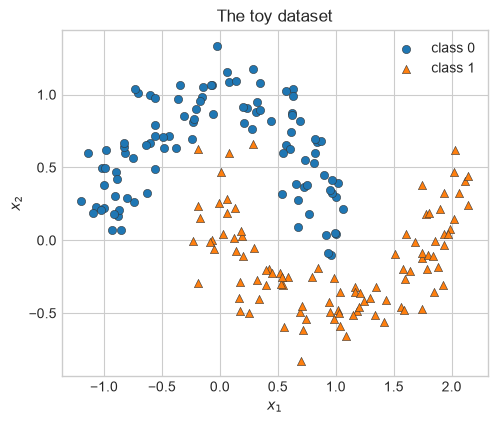

In [16]:
# The 2D toy dataset, two interleaved point classes, frozen in the data directory.
moons = pq.read_table(data_dir / "toy_two_moons.parquet").to_pandas()
moons_x = moons[["x1", "x2"]].to_numpy()
moons_y = moons["label"].to_numpy().astype(int)

# Frozen initial weights, so everyone trains the same network.
# The file stores each weight matrix with one column per neuron. This notebook follows the
# book, with one row per neuron, so the weight matrices are transposed once here.
mlp_init = {name: value.T if "_W" in name else value
            for name, value in np.load(data_dir / "mlp_init_weights.npz").items()}


def plot_points(x, y, ax=None, title=None):
    ax = ax or plt.subplots(figsize=(5.5, 4.5))[1]
    for cls, marker, color in [(0, "o", "tab:blue"), (1, "^", "tab:orange")]:
        ax.scatter(x[y == cls, 0], x[y == cls, 1], marker=marker, color=color,
                   s=35, edgecolor="0.2", linewidth=0.4, label=f"class {cls}")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    if title:
        ax.set_title(title)
    ax.legend()
    return ax


def plot_decision_regions(predict_probs: Callable, x, y, title=None):
    # Color the plane by the probability the model gives to class 1.
    lin1 = np.linspace(x[:, 0].min() - 0.4, x[:, 0].max() + 0.4, 220)
    lin2 = np.linspace(x[:, 1].min() - 0.4, x[:, 1].max() + 0.4, 220)
    g1, g2 = np.meshgrid(lin1, lin2)
    grid = np.column_stack([g1.ravel(), g2.ravel()])
    p1 = predict_probs(grid)[:, 1].reshape(g1.shape)

    fig, ax = plt.subplots(figsize=(6.5, 5))
    cs = ax.contourf(g1, g2, p1, levels=20, cmap="RdYlBu_r", alpha=0.75, vmin=0, vmax=1)
    ax.contour(g1, g2, p1, levels=[0.5], colors="black", linewidths=1.5)
    fig.colorbar(cs, ax=ax, label="p(class 1)")
    plot_points(x, y, ax=ax, title=title)


plot_points(moons_x, moons_y, title="The toy dataset")
plt.show()

### 3a. Shapes

Before you continue to training the neural network you will reason through the structure of the associated vectors and matrices first.
Working with the correct array shapes is a large part of implementing a network, so start on paper.
Assume our network has $d = 2$ inputs, $d_1 = 16$ hidden units and $c = 2$ classes, and processes a batch of $n = 128$ examples.

__Task:__ Write the shapes of $W^{(1)}$, $\mathbf{b}^{(1)}$, $Z_1$, $A$, $W^{(2)}$, $Z_2$ and $P$ to ANS, and the total number of trainable parameters (all entries of $W^{(1)}, \mathbf{b}^{(1)}, W^{(2)}, \mathbf{b}^{(2)}$).



$W^{(1)}$ (16,2)

$\mathbf{b}^{(1)}$ (16,)

$Z_1$ (128,16)

$A$ (128,16)

$W^{(2)}$ (2,16)

$Z_2$ (128,2)

$P$ (128,2)

82

### 3b. The forward pass

Now that you understand the structure of the network you are going to implement the _forward pass_.
The idea is to take a batch of input data, calculate all the intermediate neuron activations one layer at a time, and then return as output the probabilities of each class.
To be clear, you will not train the network yet, but rather run a forward pass on the untrained network. 

__Task:__ Implement `relu`, `softmax` and `forward` from the formulas in the intro.
`forward` needs to return the final probabilities and all the intermediate arrays $Z_1, A, Z_2, P$.
You will need them later when implementing the _backward pass_ to train the model weights.
The setup code calculates the accuracy of the untrained network.
Write the accuracy to ANS.

In [17]:
# The one-hot matrix Y for the toy labels
moons_Y = np.eye(2)[moons_y]

In [18]:
# TODO: Implement the forward pass.

def relu(z: np.ndarray) -> np.ndarray:
    return np.maximum(0, z)


def softmax(z: np.ndarray) -> np.ndarray:
    z = z - z.max(axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

def forward(X: np.ndarray, W1: np.ndarray, b1: np.ndarray,
            W2: np.ndarray, b2: np.ndarray) -> tuple:
    Z1 = X @ W1.T + b1
    A = relu(Z1)
    Z2 = A @ W2.T + b2
    P = softmax(Z2)

    return Z1, A, Z2, P

In [19]:
print("3b. The forward pass")
Z1_init, A_init, Z2_init, P_init = forward(
    moons_x, mlp_init["toy_W1"], mlp_init["toy_b1"], mlp_init["toy_W2"], mlp_init["toy_b2"])
print(f"\tAccuracy at the initial weights: {(P_init.argmax(axis=1) == moons_y).mean()}")

3b. The forward pass
	Accuracy at the initial weights: 0.21


### 3c. The backward pass

In order to train the neural network you are going to iteratively update the model parameters using gradient descent.
Therefore your next task is to calculate the gradients for the weights and the biases in the model, or weights for short, with respect to a loss function.

This is done in the _backward pass_.
Performing this step should feel similar to calculating the gradients for the regression models in assignment 1. 
However, there is a slight difference in implementing this process when working with neural networks.

The weights of the regression models in assignment 1 could be updated all at once, as long as the gradient of the loss was available. 
We still need a loss, and we still need to calculate the gradient of the model weights with respect to that loss.
However with a neural network we need to do so _layer by layer_, starting from the "back" and "propagating" the updates toward the "front" of the network.

In [20]:
from assignment_2_demos import show_backprop

show_backprop()

### The loss

To implement a backward pass you need a loss function. 
Remember that a loss function should give a lower value as the prediction error decreases.

The output for a single prediction is a vector $\mathbf{p}$ that contains the predicted probability for each class.
The true probability is represented by vector $\mathbf{e}_y$, which contains $1$ for the true class $y$ and $0$ for all the other class entries.
This scheme of encoding the output is called _one-hot encoding_.
If you run a forward pass on an entire batch of inputs at once you get the matrices $Y$ and $P$ again, where the rows correspond to the size of the batch.

The __cross entropy__ loss $\mathcal{L}$ is often used for classification tasks and makes use of both the model predictions $P$ and the ground truth $Y$

$$\mathcal{L} = -\frac{1}{n} \sum_{i=1}^{n} \log P_{iy_i}
    = -\frac{1}{n} \sum_{i=1}^{n} \sum_{l=1}^{c} Y_{il} \log P_{il}$$

where $y_i$ is the true class of example $i$.

It takes the negative logarithm of the predicted probabilities $P$, which is $0$ when the probability is $1$ and tends to $\infty$ as the probability tends to $0$.
It then multiplies those values by the ground truth $Y$, thus reducing all the "incorrect" entries to $0$ except the loss for the true class.
Finally it sums over the entire batch $n$ and all $c$ classes, then normalizes that value over the batch size by taking the mean.
This final step improves computational stability over different batch sizes. 

Cross entropy loss is thus $0$ when the model puts probability $1$ on the true class, and it grows without bound as the model gets more predictions wrong.
One caveat is that when the model predicts $1$ for _every class at once_ the loss is also $0$.
That is why it is important to use a softmax layer to provide a valid probability distribution for every row in $P$ when using cross entropy loss.

### The gradients

Now we would like to know the gradients of the loss with respect to our update parameters $W^{(1)}, \mathbf{b}^{(1)}, W^{(2)}, \mathbf{b}^{(2)}$ so we can update them during training.
We cannot calculate those directly since the loss is not directly calculated using the parameters but using $Z_2$. 
Therefore we need to use the chain rule to calculate them all. 

The first step is calculating the gradient for cross entropy with softmax activation, which luckily for us is fairly straightforward

$$\frac{\partial \mathcal{L}}{\partial Z_2} = \frac{1}{n}(P - Y)$$

The same pattern continues backwards through the network, which is why the procedure is called __backpropagation__.

$$\frac{\partial \mathcal{L}}{\partial W^{(2)}} = \Big(\frac{\partial \mathcal{L}}{\partial Z_2}\Big)^\top A, \qquad
  \frac{\partial \mathcal{L}}{\partial \mathbf{b}^{(2)}} = \text{column sums of } \frac{\partial \mathcal{L}}{\partial Z_2}$$

$$\frac{\partial \mathcal{L}}{\partial A} = \frac{\partial \mathcal{L}}{\partial Z_2} W^{(2)}, \qquad
  \frac{\partial \mathcal{L}}{\partial Z_1} = \frac{\partial \mathcal{L}}{\partial A} \circ [Z_1 > 0]$$

$$\frac{\partial \mathcal{L}}{\partial W^{(1)}} = \Big(\frac{\partial \mathcal{L}}{\partial Z_1}\Big)^\top X, \qquad
  \frac{\partial \mathcal{L}}{\partial \mathbf{b}^{(1)}} = \text{column sums of } \frac{\partial \mathcal{L}}{\partial Z_1}$$

The derivative $\mathrm{ReLU}'$ of the ReLU activation is not continuous: it is $1$ where $Z_1 > 0$ and $0$ elsewhere, which is written as $[Z_1 > 0]$.
The gradient is thus set to $0$ wherever the hidden unit was inactive.
In other words the gradient only flows through a hidden unit where the unit was active.

__Task:__ Implement `backward`.
It takes the intermediate matrices produced by `forward` and produces the gradient of the loss with respect to each of the four parameters $W^{(1)}, \mathbf{b}^{(1)}, W^{(2)}, \mathbf{b}^{(2)}$.
Write the gradient entries printed by the setup code to ANS.

_Optional:_ You can verify your implementation by checking your gradient implementation with a finite difference approach, a numerical way to calculate the gradient. It is more computationally expensive, but can be used for verification purposes. It changes a weight by a small $\varepsilon$, measures how much the loss changes and uses that to compute a gradient, and compares that to the value computed by `backward`.

In [21]:
# TODO: Implement the backward pass from the formulas in the intro.

def cross_entropy(P: np.ndarray, Y: np.ndarray) -> float:
    P_safe = np.clip(P, 1e-12, 1.0)
    return -np.sum(Y * np.log(P_safe)) / P.shape[0]


def backward(X: np.ndarray, Y: np.ndarray, Z1: np.ndarray,
             A: np.ndarray, P: np.ndarray, W2: np.ndarray) -> tuple:

    n = X.shape[0]

    dZ2 = (P - Y) / n

    dW2 = dZ2.T @ A
    db2 = np.sum(dZ2, axis=0)

    dA = dZ2 @ W2
    dZ1 = dA * (Z1 > 0)

    dW1 = dZ1.T @ X
    db1 = np.sum(dZ1, axis=0)

    return dW1, db1, dW2, db2

In [22]:
print("3c. The backward pass")
loss_init = cross_entropy(P_init, moons_Y)
print(f"\tLoss at the initial weights: {loss_init}\n")

dW1, db1, dW2, db2 = backward(moons_x, moons_Y, Z1_init, A_init, P_init, mlp_init["toy_W2"])
print(f"\tdL/dW1[0, 0]: {dW1[0, 0]}")
print(f"\tdL/db1[0]:    {db1[0]}")
print(f"\tdL/dW2[0, 0]: {dW2[0, 0]}")
print(f"\tdL/db2[0]:    {db2[0]}")

3c. The backward pass
	Loss at the initial weights: 1.0631904516699995

	dL/dW1[0, 0]: -0.061110710598791876
	dL/db1[0]:    0.06314264126086874
	dL/dW2[0, 0]: -0.12083788568596812
	dL/db2[0]:    0.09355740413652967


### 3d. Training on the toy data

Now you can use the gradients to update the network parameters and implement a training loop. 

__Task:__ Fill in the training loop in `train_mlp`.
Each step runs `forward`, records the loss, runs `backward`, and moves all four parameters one step against their gradients using step size $\eta$ = `q_eta_3d`. 
Write the loss and the training accuracy after the last step to ANS.

In [23]:
q_eta_3d = 0.5
q_steps_3d = 2000
q_report_steps_3d = [0, 100, 1000, 2000]

In [24]:
# TODO: Implement the training loop.

def train_mlp(X: np.ndarray, y: np.ndarray,
              W1: np.ndarray, b1: np.ndarray, W2: np.ndarray, b2: np.ndarray,
              eta_const: float, max_steps: int) -> tuple:
    # Work on copies so the frozen initial weights stay untouched.
    W1, b1 = np.array(W1, dtype=np.float64), np.array(b1, dtype=np.float64)
    W2, b2 = np.array(W2, dtype=np.float64), np.array(b2, dtype=np.float64)
    Y = np.eye(W2.shape[0])[y]
    eta = float(eta_const)
    losses = np.empty(max_steps + 1, dtype=np.float64)
    
    # Implement training code from here forward
    for step in range(max_steps):
        # Forward propagation
        Z1, A, Z2, P = forward(X, W1, b1, W2, b2)

        # Record the loss
        losses[step] = cross_entropy(P, Y)

        # Backpropagation
        dW1, db1, dW2, db2 = backward(
            X, Y, Z1, A, P, W2
        )

        # Gradient descent
        W1 -= eta * dW1
        b1 -= eta * db1
        W2 -= eta * dW2
        b2 -= eta * db2

    # Record the loss after the final update
    Z1, A, Z2, P = forward(X, W1, b1, W2, b2)
    losses[max_steps] = cross_entropy(P, Y)

    # Do not forget to record the loss one last time outside the loop
    # losses[max_steps] = ...
    return (W1, b1, W2, b2), losses

3d. Training on the toy data
	Loss after 0 steps: 1.0631904516699995
	Loss after 100 steps: 0.2078291470667785
	Loss after 1000 steps: 0.0233719984219675
	Loss after 2000 steps: 0.013532143623395996
	Training accuracy after 2000 steps: 0.995


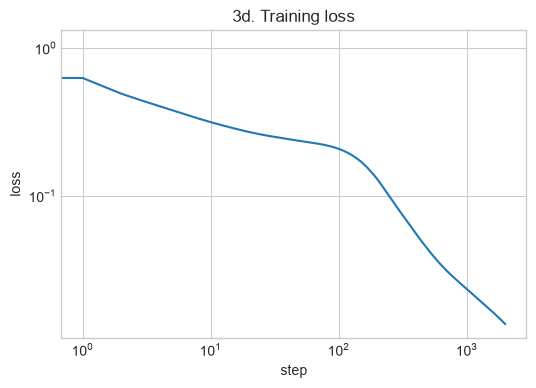

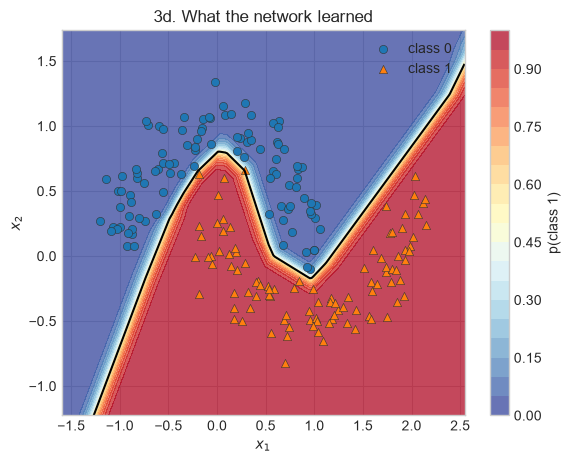

In [25]:
print("3d. Training on the toy data")
toy_params, toy_losses = train_mlp(
    moons_x, moons_y, mlp_init["toy_W1"], mlp_init["toy_b1"],
    mlp_init["toy_W2"], mlp_init["toy_b2"], q_eta_3d, q_steps_3d)

for step in q_report_steps_3d:
    print(f"\tLoss after {step} steps: {toy_losses[step]}")

_, _, _, P_toy = forward(moons_x, *toy_params)
toy_accuracy = (P_toy.argmax(axis=1) == moons_y).mean()
print(f"\tTraining accuracy after {q_steps_3d} steps: {toy_accuracy}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(toy_losses)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("step"); ax.set_ylabel("loss")
ax.set_title("3d. Training loss")
plt.show()

plot_decision_regions(lambda grid: forward(grid, *toy_params)[3], moons_x, moons_y,
                      title="3d. What the network learned")
plt.show()

The decision boundary is curved, which cannot happen by using a linear model on $(x_1, x_2)$ without any polynomial features.
The network learned the features it needed during training by using the non-linear ReLU activations.

### 3e. Reading handwritten digits

The same code should scale from a toy problem with 200 samples to an actual image classification dataset.
The setup loads a subset of the MNIST number classification dataset.
The inputs are $28 \times 28$ gray images, flattened to 784 features, with pixel values scaled to $[0, 1]$.
The network sizes change.
One input is now a vector of $784$ entries, the middle layer has $32$ neurons and the output has $10$ classes.
Nothing else changes.

__Task:__ Train the MNIST network with your `train_mlp` and the frozen initial weights `mnist_W1` … `mnist_b2`, using the settings in the setup code.
The setup code measures accuracy on the test images and shows a gallery of predictions.
Write the training loss after the last step and the test accuracy to ANS.

In [26]:
q_eta_3e = 0.5
q_steps_3e = 500
report_row_3e = 123  # a row of the MNIST test set

mnist_train = pq.read_table(data_dir / "mnist_train.parquet").to_pandas()
mnist_test = pq.read_table(data_dir / "mnist_test.parquet").to_pandas()

mnist_train_x = mnist_train.drop(columns="label").to_numpy() / 255.0
mnist_train_y = mnist_train["label"].to_numpy().astype(int)
mnist_test_x = mnist_test.drop(columns="label").to_numpy() / 255.0
mnist_test_y = mnist_test["label"].to_numpy().astype(int)

print(f"Train images: {mnist_train_x.shape}, test images: {mnist_test_x.shape}")

# This cell takes on the order of ten seconds.

Train images: (5000, 784), test images: (1000, 784)


In [27]:
# TODO: train the MNIST network with your train_mlp from 3d.
mnist_params, mnist_losses = train_mlp(
    mnist_train_x,
    mnist_train_y,
    mlp_init["mnist_W1"],
    mlp_init["mnist_b1"],
    mlp_init["mnist_W2"],
    mlp_init["mnist_b2"],
    q_eta_3e,
    q_steps_3e
)

3e. Reading handwritten digits
	Training loss after 500 steps: 0.06152024599959071
	Training accuracy: 0.9886
	Test accuracy:     0.915
	Test row 123: predicted 6 (P = 0.998), actually 6


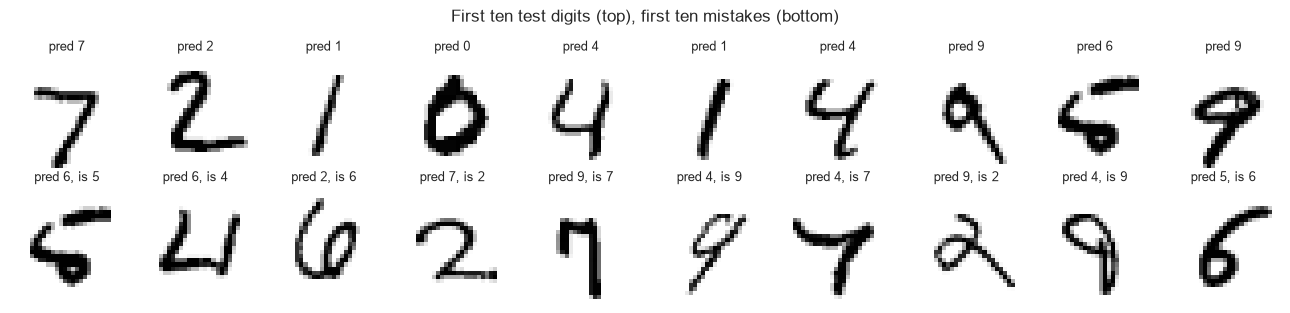

In [28]:
print("3e. Reading handwritten digits")
print(f"\tTraining loss after {q_steps_3e} steps: {mnist_losses[q_steps_3e]}")

_, _, _, P_mnist_train = forward(mnist_train_x, *mnist_params)
_, _, _, P_mnist_test = forward(mnist_test_x, *mnist_params)
mnist_train_accuracy = (P_mnist_train.argmax(axis=1) == mnist_train_y).mean()
mnist_test_accuracy = (P_mnist_test.argmax(axis=1) == mnist_test_y).mean()
print(f"\tTraining accuracy: {mnist_train_accuracy}")
print(f"\tTest accuracy:     {mnist_test_accuracy}")

row_p = P_mnist_test[report_row_3e]
print(f"\tTest row {report_row_3e}: predicted {row_p.argmax()} "
      f"(P = {row_p.max():.3f}), actually {mnist_test_y[report_row_3e]}")

# A gallery of the first ten test digits and the first ten the network gets wrong.
wrong = np.flatnonzero(P_mnist_test.argmax(axis=1) != mnist_test_y)
fig, axes = plt.subplots(2, 10, figsize=(13, 3.2))
for ax, i in zip(axes[0], range(10)):
    ax.imshow(mnist_test_x[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"pred {P_mnist_test[i].argmax()}", fontsize=9)
    ax.axis("off")
for ax, i in zip(axes[1], wrong[:10]):
    ax.imshow(mnist_test_x[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"pred {P_mnist_test[i].argmax()}, is {mnist_test_y[i]}", fontsize=9)
    ax.axis("off")
fig.suptitle("First ten test digits (top), first ten mistakes (bottom)")
plt.tight_layout()
plt.show()

# Part II: Unsupervised Learning

In the second part of assignment two you will focus on a number of unsupervised learning approach.

## 4. Matrix completion

### Solving least squares

In assignment 1's exercise 4c, you fitted three parameters with 100,000 gradient steps. 
For problems of that shape, there is a direct method. 
You derived the gradient of the mean squared error (MSE) in 6b.

$$\nabla \text{MSE}(\boldsymbol\beta) = \frac{2}{n} X^\top (X \boldsymbol\beta - \mathbf{y})$$

where $\boldsymbol\beta$ is the parameter vector (called $w$ in assignment 1).

Based on the __first order necessary condition__ (FONC), we know the gradient at a minimum of a smooth function must be zero. We used the same fact to find the critical points in assignment 1's 3b. 
For this objective, the problem is defined by a linear system which we can solve analytically:
$$X^\top (X\boldsymbol\beta - \mathbf{y}) = 0 \iff X^\top X\, \boldsymbol\beta = X^\top \mathbf{y}$$

This analytical solution requires no iteration and no step size. It works because the MSE is convex. Before the matrix completion exercise, 4a applies this solution to two problems from assignment 1.

In the following exercise, you can use `np.linalg.solve(M, v)` instead of `np.linalg.inv(M) @ v`, as it is often faster and numerically more accurate than forming an inverse. An explicit inverse is almost never necessary.

### 4a. The exact answer

__Task:__ Implement `solve_least_squares`, then use it to solve the two regression problems from assignment 1.

- The toy quadratic of assignment 1's 4a–4c, the ten data points with the design matrix $X = [x^2,\ x,\ 1]$.
- The housing regression of assignment 1's 6c, the standardized design matrix over the training districts.

Write the exact $a$, $b$, $c$, and loss of the toy problem to ANS, and the exact housing training loss. 
Compare them with what your gradient descent found in assignment 1.

In [29]:
# The toy dataset of assignment 1, section 4.
toy_data_x = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0])
toy_data_y = np.array([20.3, 12.5, 9.0, 4.1, 3.6, 2.2, 4.9, 6.5, 12.4, 17.3])
X_toy = np.column_stack([toy_data_x**2, toy_data_x, np.ones_like(toy_data_x)])

# The housing design matrix of assignment 1's 6a.
train_mean = np.mean(features_train_raw, axis=0)
train_std = np.std(features_train_raw, axis=0)
X_housing = np.hstack([np.ones((len(features_train_raw), 1)),
                       (features_train_raw - train_mean) / train_std])
y_housing = price_train

In [30]:
# TODO: Solve X^T X beta = X^T y directly.

def solve_least_squares(X: np.ndarray, y: np.ndarray) -> np.ndarray:
    #pass # Implement here (one call to np.linalg.solve)
    return np.linalg.solve(X.T @ X, X.T @ y)

In [31]:
print("4a. The exact answer, twice")

abc = solve_least_squares(X_toy, toy_data_y)
toy_loss = np.mean((X_toy @ abc - toy_data_y) ** 2)
print(f"\tToy problem: a = {abc[0]}, b = {abc[1]}, c = {abc[2]}")
print(f"\tToy loss at the exact minimum: {toy_loss}")

w_housing = solve_least_squares(X_housing, y_housing)
housing_loss = np.mean((X_housing @ w_housing - y_housing) ** 2)
print(f"\n\tHousing training loss at the exact minimum: {housing_loss}")

4a. The exact answer, twice
	Toy problem: a = 0.794318181818184, b = -8.97507575757578, c = 28.061666666666707
	Toy loss at the exact minimum: 0.42824696969697074

	Housing training loss at the exact minimum: 0.5239984048506415


### The Netflix problem

In this exercise, we implement an [Advanced Recommender System](https://tue-ml.github.io/book/dim-reduction-mf/#a-more-advanced-recommender-system).

Imagine you work at a streaming service, where the product manager asks the following question.

> "We want to recommend movies, but most people rate very few movies.
> Out of thousands of movies, a user may rate five or ten.
> Can we still figure out what they would like?"

Put the ratings in a matrix $D$: one row per user ($n$ rows), one column per movie ($d$ columns), $D_{ik}$ the rating user $i$ gave movie $k$, and 0 where there is no rating. 
Most entries are 0. 
Predicting the missing entries is the __matrix completion__ problem.

### Low rank approximations

As discussed in the matrix factorization lecture, the key assumption is that taste has low-dimensional structure. A user's preferences can be summarized by $r$ properties, for example, how much they like action films, and a movie can be summarized by how much it exhibits each of those $r$ properties.
We do not define these properties by hand; we learn them from the data.

More formally, we are looking for matrices $Y \in \mathbb{R}^{n \times r}$ and  $X \in \mathbb{R}^{d \times r}$ such that
$$D \approx Y X^\top, \qquad Y \in \mathbb{R}^{n \times r}, \quad X \in \mathbb{R}^{d \times r},$$
where row $i$ of $Y$ is user $i$'s taste vector and row $k$ of $X$ is movie $k$'s property vector. Their inner product $Y_{i\cdot} X_{k\cdot}^\top$ is the predicted rating of user $i$ for movie $k$, including for user-movie pairs that were never rated, which is the goal of our task.

The key to our approach is that we judge the approximation only on the observed ratings.
Let $O \in \{0, 1\}^{n \times d}$ represent the observed entries and $\circ$ the element-wise product. We formalize the objective as
$$\min_{X, Y}\ \|O \circ (D - YX^\top)\|^2 = \sum_{(i,k):\, O_{ik} = 1} \big(D_{ik} - Y_{i\cdot} X_{k\cdot}^\top\big)^2$$

### Block coordinate descent

As we have seen in the lecture, this objective is not convex in $(X, Y)$. 
Nonetheless, if we __fix $Y$, it becomes convex in $X$__, and vice versa. 
This means we can take a coordinate descent approach to solve the problem. In general terms, we iteratively apply the following updates:
$$\begin{aligned}
X' = \arg\min_{X}\ \|O \circ (D - YX^\top)\|^2 \\
Y' = \arg\min_{Y}\ \|O \circ (D - YX^\top)\|^2 
\end{aligned}$$

The strategy is called __block coordinate descent__. Fix everything except one block, solve that block analytically, move to the next block, and cycle until there are no further improvements. 
A key characteristic of this approach is that no update can increase the objective, as each update lands on the exact minimum for its block.

Although each block problem is convex, it may not have a single solution, for example for users with fewer than $r$ ratings, similar to the cases [where $p \gg n$ in linear regression](https://tue-ml.github.io/book/regression-overparameterized/). 
As we have seen in the regularization lecture, we can mitigate such issues by adding a __regularization__ penalty to the objective:
$$\min_{X, Y}\ \|O \circ (D - YX^\top)\|^2 + \lambda\|X\|^2 + \lambda\|Y\|^2 = \sum_{(i,k):\, O_{ik} = 1} \big(D_{ik} - Y_{i\cdot} X_{k\cdot}^\top\big)^2 + \lambda\|X\|^2 + \lambda\|Y\|^2.$$
We will investigate the effects of the penalization weight $\lambda$ in exercises 4c and 4d.

As discussed in the book, we can update one row at a time.
Based on the [corresponding theorem](https://tue-ml.github.io/book/dim-reduction-mf/#thm-low-rank-mf-minimizers), the update for each row is given by 
$$X_{k\cdot} \leftarrow D_{\cdot k}^\top \mathrm{diag}(O_{\cdot k})\, Y \big(Y^\top \mathrm{diag}(O_{\cdot k})\, Y + \lambda I\big)^{-1}$$
and 
$$Y_{i\cdot} \leftarrow D_{i\cdot} \mathrm{diag}(O_{i\cdot})\, X\, (X^\top \mathrm{diag}(O_{i\cdot})\, X + \lambda I)^{-1}$$
Putting it all together, we have the full algorithm:
$$
\begin{array}{l}
\textbf{function } \text{MatrixCompletion}(D, r;\ t_{max}, \lambda): \\
\hspace{1em} (X, Y) \leftarrow \text{initial matrices} \\
\hspace{1em} O \leftarrow \text{indicator of the nonzero entries of } D \\
\hspace{1em} \textbf{for } t \in \{1, \ldots, t_{max}\}: \\
\hspace{3em} \textbf{for } k \in \{1, \ldots, d\}: \quad X_{k\cdot} \leftarrow D_{\cdot k}^\top \mathrm{diag}(O_{\cdot k})\, Y\, (Y^\top \mathrm{diag}(O_{\cdot k})\, Y + \lambda I)^{-1} \\
\hspace{3em} \textbf{for } i \in \{1, \ldots, n\}: \quad Y_{i\cdot} \leftarrow D_{i\cdot} \mathrm{diag}(O_{i\cdot})\, X\, (X^\top \mathrm{diag}(O_{i\cdot})\, X + \lambda I)^{-1} \\
\hspace{1em} \textbf{return } (X, Y)
\end{array}
$$
In exercise 6, we use the same strategy to implement k-means based on different blocks: cluster assignments and centroids.

### 4b. Implementing matrix completion

The data is the [MovieLens](https://grouplens.org/datasets/movielens/) small dataset, filtered to movies with more than 100 ratings and users with at least 5 of those (the setup prints the result). 
Since this approach is sensitive to the initialization of $X$ and $Y$, we initialize $X_0, Y_0$ with matrices from the data directory, so everyone computes the same answer.

__Task:__ Implement `observed_mse` and the two block-update lines in `matrix_completion`.
Use `np.linalg.solve`, not `np.linalg.inv`, as in 4a. The update is written with an inverse, but $M^{-1}\mathbf{v}$ is computed as `solve(M, v)`. The matrix in this update is symmetric, so the row equation transposes cleanly.

Write the mean squared error on the observed entries after the last round to ANS, together with the predicted ratings of the first user for the four movies in the setup code (the user already rated three of these movies).

In [32]:
q_r_4b = 20
q_t_max_4b = 50
q_lambda_4b = 0.1
q_movies_4b = [
    "Jumanji (1995)",
    "Fight Club (1999)",
    "Matrix, The (1999)",
    "Monty Python and the Holy Grail (1975)"
]

ratings_table = pq.read_table(data_dir / "movielens_ratings.parquet").to_pandas()
movies_table = pq.read_table(data_dir / "movielens_movies.parquet").to_pandas()

user_ids = ratings_table["userId"].to_numpy()
movie_ids = np.array([int(c) for c in ratings_table.columns[1:]])
D_ratings = ratings_table.drop(columns="userId").to_numpy()
n_users, n_movies = D_ratings.shape

mc_init = np.load(data_dir / "matrix_completion_init.npz")

print(f"Rating matrix: {n_users} users x {n_movies} movies, "
      f"{(D_ratings > 0).mean():.1%} of entries observed")


title_to_column = {title: j
                   for title, movie_id in zip(movies_table["title"], movies_table["movieId"])
                   for j, mid in enumerate(movie_ids) if mid == movie_id}


def get_predicted_ratings(titles: list, X: np.ndarray, Y: np.ndarray, user: int = 0) -> dict:
    return {title: float(Y[user] @ X[title_to_column[title]]) for title in titles}

# Expect this cell to take a few seconds once implemented.

Rating matrix: 556 users x 134 movies, 26.4% of entries observed


In [33]:
# TODO: Implement observed_mse and the two block updates from the pseudocode.

def observed_mse(D: np.ndarray, O: np.ndarray, X: np.ndarray, Y: np.ndarray) -> float:
    # ||O o (D - Y X^T)||^2 divided by the number of observed entries.
    # Note: you should not include the regularization penalties
    #pass # Implement here
    residual = O * (D - Y @ X.T)
    return np.sum(residual ** 2) / O.sum()


def matrix_completion(D: np.ndarray, r: int, t_max: int, lambd: float,
                      X0: np.ndarray, Y0: np.ndarray) -> tuple:
    X, Y = np.array(X0, dtype=np.float64), np.array(Y0, dtype=np.float64)
    O = (D > 0).astype(np.float64)
    reg = lambd * np.eye(r)
    losses = np.empty(t_max, dtype=np.float64)

    for t in range(t_max):
        for k in range(D.shape[1]):
            O_Xk = O[:, k, None]  # O_Xk * Y is np.diag(O[:, k]) @ Y
            X[k, :] = None  # Implement here
        for i in range(D.shape[0]):
            O_Yi = O[i, :, None]  # O_Yi * X is np.diag(O[i, :]) @ X
            Y[i, :] = None  # Implement here
        losses[t] = observed_mse(D, O, X, Y)

    return X, Y, losses

4b. Implementing matrix completion
	Observed MSE after 50 rounds: nan

	Predicted ratings for the first user (userId 1):
		Jumanji (1995): nan (never rated: this is a predicted missing entry)
		Fight Club (1999): nan (rated 5.0)
		Matrix, The (1999): nan (rated 5.0)
		Monty Python and the Holy Grail (1975): nan (rated 5.0)


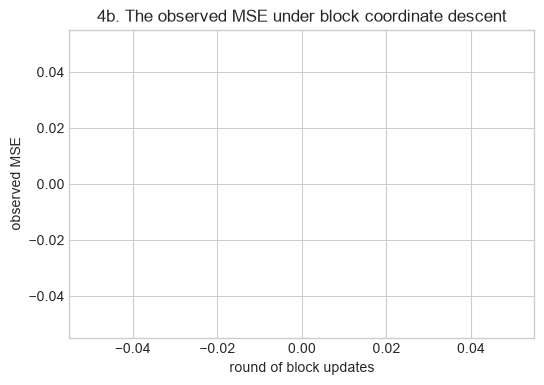

In [34]:
print("4b. Implementing matrix completion")
X_mc, Y_mc, mc_losses = matrix_completion(
    D_ratings, q_r_4b, q_t_max_4b, q_lambda_4b, mc_init["X0"], mc_init["Y0"])

print(f"\tObserved MSE after {q_t_max_4b} rounds: {mc_losses[-1]}")
print(f"\n\tPredicted ratings for the first user (userId {user_ids[0]}):")
for title, rating in get_predicted_ratings(q_movies_4b, X_mc, Y_mc).items():
    observed = D_ratings[0, title_to_column[title]]
    note = f"(rated {observed})" if observed > 0 else "(never rated: this is a predicted missing entry)"
    print(f"\t\t{title}: {rating} {note}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, q_t_max_4b + 1), mc_losses, marker=".")
ax.set_xlabel("round of block updates"); ax.set_ylabel("observed MSE")
ax.set_title("4b. The observed MSE under block coordinate descent")
plt.show()

The curve never rises. Every block update solves its own least squares problem exactly, so the full objective, with the penalty terms, can only improve or stay unchanged.
The observed MSE in the plot leaves out the penalty terms, so it has no such guarantee, but here it falls as well.
Unlike gradient descent, block coordinate descent has no step size that can be set too large.

### 4c. Tuning the regularization parameter

In this exercise, we will find the best value of the regularization weight $\lambda$. 
We will take a train-test approach.

First, we select $n_{\text{test}} = 1000$ observed ratings from the rating matrix $D$. Each rating is one entry $D_{ik}$: the rating of user $i$ for movie $k$. We select these entries at random from all observed entries, so they do not belong to specific users or movies. In the training matrix, we set these entries to 0, which is the value for a missing rating. Then we fit the model on the training matrix. The removed ratings are the test set.
Because the randomly selected test set may affect the results, we repeat the entire procedure `n_repetitions` times using different random samples of removed ratings.

__Task:__ For each of the `n_repetitions` test sets and for each value of $\lambda$:

1. Run the matrix completion algorithm on the training matrix.
2. Use the resulting factorization to predict the removed ratings.
3. Compute the prediction error on the removed ratings using the mean absolute error (MAE):
$$
\text{MAE}=\frac{1}{n_{\text{test}}}\sum_{(i,k):\, O^{\text{test}}_{ik} = 1} \left|Y_{i\cdot}X_{k\cdot}^\top-D_{ik}\right|,
$$
where $O^{\text{test}}_{ik} = 1$ for the removed ratings.

You can use the matrix completion function, where `lam` is one of the lambda values:
```python
X_l, Y_l, losses_l = matrix_completion(training_dataset, q_r_4b, q_t_max_4b, lam, mc_init["X0"], mc_init["Y0"])
```

Run the plot cell below to see how the regularization term affects the MAE.
Answer the multiple choice question.

In [35]:
def mae(x:np.array, y: np.array):
    return np.abs(x-y).mean()


In [36]:
# configurations
n_test = 1000
n_repetitions = 5
rng = np.random.default_rng(0)  # the same test sets for everyone
lambda_values = [0.1, 1, 10, 100]

results = {lam: np.zeros(n_repetitions) for lam in lambda_values}

# Identify observed entries
non_zero_rows, non_zero_cols = np.nonzero(D_ratings)    


for repeat in tqdm(range(n_repetitions), desc="test sets"):
    # Sample entries to remove 
    random_idx = rng.choice(len(non_zero_rows), size=n_test, replace=False)
    sampled_rows, sampled_cols = non_zero_rows[random_idx], non_zero_cols[random_idx]

    # Create training data by removing sampled entries
    training_dataset = D_ratings.copy()
    training_dataset[sampled_rows, sampled_cols] = 0
    
    
    # Original values used as test targets
    test_values = D_ratings[sampled_rows, sampled_cols]


    # TODO: compute the MAE of every lambda for this test set
    for lam in lambda_values:      
        #pass
        # results[lam][repeat] = ??
        X_l, Y_l, losses_l = matrix_completion(
        training_dataset,
        q_r_4b,
        q_t_max_4b,
        lam,
        mc_init["X0"],
        mc_init["Y0"]
        )

        predictions = np.sum(
        Y_l[sampled_rows] * X_l[sampled_cols],
        axis=1
        )

    results[lam][repeat] = mae(predictions, test_values)

test sets: 100%|██████████| 5/5 [00:00<00:00,  6.95it/s]


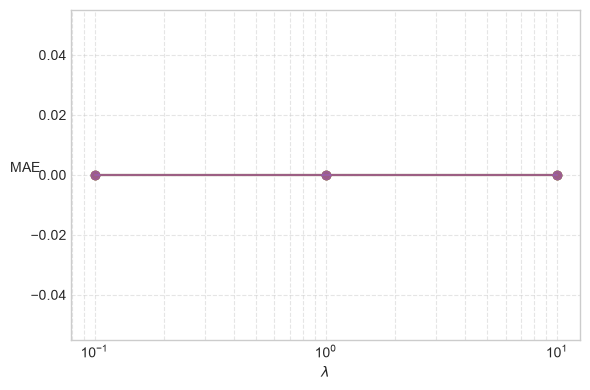

In [37]:
fig, ax = plt.subplots(figsize=(6, 4))

x = np.array(sorted(results.keys()))
values = np.stack([results[k] for k in x])

for seed in range(values.shape[1]):
    ax.plot(x, values[:, seed], marker="o", alpha=0.6)

ax.set_xscale("log")
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel("MAE", rotation=0)
ax.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

#### Multiple choice

__Question.__ Which value of $\lambda$ would be most suitable for the given dataset based on the MAE?

- __A.__ 0.1
- __B.__ 1
- __C.__ 10
- __D.__ 100

__Answer:__ ☐ A ☐ B ☐ C ☐ D

C

### 4d. Conclusions about $\lambda$

In 4c you identified the value of $\lambda$ that yields the smallest average MAE.

__Question.__ What is the most appropriate conclusion?

- __A.__ The model should always use that value of $\lambda$, regardless of the dataset.
- __B.__ The selected value of $\lambda$ achieves the best trade-off between fitting the observed ratings and avoiding overfitting on this dataset.
- __C.__ Larger values of $\lambda$ always lead to better predictions.
- __D.__ The final latent matrices $X$ and $Y$ are independent of $\lambda$.
  
__Answer:__ ☐ A ☐ B ☐ C ☐ D

B

### 4e. Similar tastes

So far, we have used the ratings matrix to predict ratings for movies that users have not yet rated. We can also use the learned user representations to investigate which users have similar or different tastes. In this question, we will compare users based on the distance between their learned representations and then check whether these distances correspond to similarities or differences in their actual movie ratings.

__Task:__ Find the users whose tastes are most similar to and most different from the first user, based on the L1 distance $\lvert Y_{1\cdot} - Y_{j\cdot}\rvert$ between their rows of the user matrix $Y$ from 4b. You do not need the full reconstruction matrix for this.
Write the IDs of the closest and farthest users and the corresponding distances to ANS.

_Note:_ We can consider the number of movies two users rated similarly or differently to check if they indeed have similar or different tastes. We will consider the ratings $D_{1k}$ and $D_{jk}$ of the first user and user $j$ for movie $k$ similar if and only if $|D_{1k}-D_{jk}| \leq 0.5$.  Note that when comparing two users, we only consider the movies that both users have rated. You do not write these counts to ANS.

In [38]:
def l1_distance(x: np.array, y: np.array):
    return np.abs(x-y).sum()

def similar_ratings(x: float, y: float, threshold: float):
    if not (x and y): raise ValueError("one of the ratings is 0, meaning not provided")
    return abs(x-y) <= threshold

def closest_and_farthest_users(Y):
    """ 
    Find the users whose representations are closest to and farthest from user 0.
    """
    # User 0 is the reference user, so we start at user 1.
    closest_user, farthest_user = 1, 1
    smallest_distance, largest_distance = float('inf'), 0

    # TODO find the closest_user and farthest_user in the list range(1,len(user_ids))
    #

    distances = np.abs(Y[1:] - Y[0]).sum(axis=1)

    closest_user = int(np.argmin(distances)) + 1
    farthest_user = int(np.argmax(distances)) + 1

    smallest_distance = float(distances.min())
    largest_distance = float(distances.max())

    
    # return the index of the user in Y (not the id)
    return closest_user, farthest_user, smallest_distance, largest_distance

def count_similar_and_different_ratings(another_user, D, threshold=0.5):
    """
    Count similar and different ratings between user 0 and another_user.
    """
    num_similar, num_different = 0, 0
    
    # (optional) TODO
    # Compare only movies rated by BOTH users.
    # Count how many ratings are similar and how many are different
    
    return num_similar, num_different

In [39]:
# collecting the results


results_4e = closest_and_farthest_users(Y_mc)

print("The userId of the closest user is {0} with a distance of {2:.3f}, and of the farthest user is {1} with a distance of {3:.3f}".format(
    user_ids[results_4e[0]], user_ids[results_4e[1]], results_4e[2], results_4e[3]))        
print("The closest user has {} similar ratings and {} different ratings to the first user".format(*count_similar_and_different_ratings(results_4e[0], D_ratings)))
print("The farthest user has {} similar ratings and {} different ratings to the first user".format(*count_similar_and_different_ratings(results_4e[1], D_ratings)))

The userId of the closest user is 2 with a distance of nan, and of the farthest user is 2 with a distance of nan
The closest user has 0 similar ratings and 0 different ratings to the first user
The farthest user has 0 similar ratings and 0 different ratings to the first user


## 5. PCA and anomaly detection

In this section, we consider __principal component analysis__, a problem with the same factorization as in section 4, but with different constraints. 
The factorization is still $D \approx YX^\top$, but now every entry is observed, and the columns of $X$ are required to be __orthogonal directions__, ordered by how much of the data variance they capture. 
PCA is unsupervised, so the data has no labels.

### The linear algebra you already did

Assignment 1 opened with four true/false statements about a centered data matrix. 
They provide two properties that are relevant for PCA: 
- (1a) The total variance of the data is $\mathrm{tr}(S)$, the sum of the eigenvalues of the covariance matrix $S$ of $D$.
- (1c) A linear transformation $DZ$, with a transformation matrix $Z \in \mathbb{R}^{d\times r}$, gives this covariance matrix for the transformed features:
$$S_{DZ} = Z^\top S Z.$$


### The PCA task

Given a data matrix $D \in \mathbb{R}^{n\times d}$, PCA chooses the linear transformation $Z$ that preserves as much of the data variance as possible (see [the book](https://tue-ml.github.io/book/dim-reduction-pca/)). 

Let $C=D -\mathbf{1}\boldsymbol{\mu}^\top$ be the [centered data matrix](https://tue-ml.github.io/book/dim-reduction-pca/#pca-var-prod), where $\boldsymbol{\mu}$ holds the mean of each column of $D$.
In practice, we can compute PCA with the [singular value decomposition](https://tue-ml.github.io/book/dim-reduction-pca/#optimization) of the centered data matrix, $C = U \Sigma V^\top$. NumPy provides it as `np.linalg.svd`.

__Fit.__
The first $r$ columns of $V$ give the linear transformation we want: $Z=V_{\cdot \mathcal{R}}$, where $\mathcal{R}=\{1,\ldots,r\}$. These columns are the __principal components__, and $Z$ plays the role of $X$ in $D \approx YX^\top$.

__Project.__
We can project the data onto a compact representation $Y$ by multiplying the data points by the principal components: 
$$Y = D Z \qquad \text{(the low-dimensional coordinates).}$$
Note that we are using the non-centered low-dimensional representation of the data.

__Reconstruction.__ When we see [PCA as a Linear Autoencoder](https://tue-ml.github.io/book/dim-reduction-pca/#pca-as-a-linear-autoencoder), we can map the coordinates back to the original space:
$$\hat{D} = Y Z^\top \qquad \text{(the reconstruction).}$$

This low-dimensional representation also lets us inspect the data. We will use this idea to detect fabricated records in a new dataset.

### The corrupted data file

The housing agency sends a new dataset of district records in the file `california_housing_anomalies.parquet`.
It is the familiar dataset, cleaned of extreme outliers on the agency's side, except that some of its rows were __fabricated__, and nobody knows which ones.

Each fabricated row is individually plausible. Each feature value lies within a normal range for that feature, so no per-feature check can find the fabricated rows. 
What these fabricated rows do not reproduce is the __relationship between the features__, for example the correlation between average rooms and average bedrooms, or between latitude and longitude. 
Principal components capture these relationships. 
A real district lies close to the principal subspace, while a fabricated one does not, and has a large __reconstruction error__:
$$\text{error}_i = \| \hat{D}_{i\cdot} - D_{i\cdot} \|^2.$$

To be clear, we planted these rows at known positions, and the file contains an `is_corrupted` column so that your detector can be evaluated. 
This is standard practice. We typically evaluate anomaly detectors on data with known anomalies before using them on data where the answer is unknown. 
Your detector must not use that column except in the final evaluation step.

In [40]:
# configurations

q_r_5 = 3
report_row_5 = 19919  # the row_id examined in 5a and 5b

anomalies_table = pq.read_table(data_dir / "california_housing_anomalies.parquet").to_pandas()
anomaly_feature_names = [c for c in anomalies_table.columns if c not in ("is_corrupted", "row_id")]
delivery = anomalies_table[anomaly_feature_names].to_numpy()
is_corrupted = anomalies_table["is_corrupted"].to_numpy()  # scoring only!

# Standardize over the whole file.
D_delivery = (delivery - np.mean(delivery, axis=0)) / np.std(delivery, axis=0)

print(f"Delivered districts: {len(delivery)}, features: {len(anomaly_feature_names)}")
print(f"Fabricated rows hidden in the file: {is_corrupted.sum()}")

Delivered districts: 20458, features: 8
Fabricated rows hidden in the file: 100


### 5a. Implementing PCA

__Task:__ Implement the three PCA functions `fit_pca`, `project` and `reconstruct` with the SVD (`np.linalg.svd`).
Then use them to compute the three values in the cell with `highest_variance_direction`.
Use the same variance estimator everywhere, either the biased or the unbiased one.
Write these three values to ANS:

1. the unit vector that points in the direction of the highest variance in the data,
2. the three low-dimensional coordinates of the row `report_row_5`,
3. the fraction of the total variance that the top $r = 3$ components capture.

The sign of a singular vector is arbitrary, because $\mathbf{v}$ and $-\mathbf{v}$ span the same direction.
The stub of `fit_pca` therefore fixes a convention: it flips each component so that its largest-magnitude entry is positive.
Without a convention, correct implementations could report the same coordinates with opposite signs.


In [41]:
# TODO: Implement PCA using truncated SVD.

def fit_pca(D: np.ndarray, r: int) -> tuple:
    mean = np.mean(D, axis=0)
    centered = D - mean

    
    _, singular_values, Vt = np.linalg.svd(
        centered, full_matrices=False
    )
    components = Vt[:r].T.copy()
    
    # TODO: implement truncated SVD.
    # SVD of `centered`. Keep the top r right singular vectors as the columns of
    # `components`, and all singular values in `singular_values`.
    #components, singular_values = np.zeros((D.shape[1], r)), np.ones(r)

    
    # The sign convention. Flip each component so its largest entry is positive.
    for j in range(components.shape[1]):
        if components[np.abs(components[:, j]).argmax(), j] < 0:
            components[:, j] = -components[:, j]
    return components, singular_values


def project(D: np.ndarray, components: np.ndarray) -> np.ndarray:
    # The low-dimensional coordinates of every row.
    
    # Implement here
    return D @ components
    #return np.zeros((len(D), components.shape[1]))


def reconstruct(Y: np.ndarray, components: np.ndarray) -> np.ndarray:
    # Back from coordinates to the original feature space.
    
    # Implement here
    return Y @ components.T
    #return np.zeros((len(Y), len(components)))


In [42]:
# TODO: compute the three values for ANS with your PCA functions.
pca_components, singular_values = fit_pca(D_delivery, q_r_5)
Y_delivery = project(D_delivery, pca_components)

#highest_variance_direction = None  # Implement here
#report_row_5_coordinates = None  # Implement here
#variance_fraction = None  # Implement here

highest_variance_direction = pca_components[:, 0]
report_row_5_coordinates = Y_delivery[report_row_5]
variance_fraction = (
    np.sum(singular_values[:q_r_5] ** 2)
    / np.sum(singular_values ** 2)
)

In [43]:
print("5a. Implementing PCA")
print(f"\tDirection with highest variance: {highest_variance_direction}")
print(f"\tCoordinates of row {report_row_5}: {report_row_5_coordinates}")
print(f"\tVariance fraction of the top {q_r_5} components: {variance_fraction}")

5a. Implementing PCA
	Direction with highest variance: [ 0.07385786  0.06210194  0.21712815  0.12463256 -0.21458904 -0.22244523
  0.6475156  -0.6428092 ]
	Coordinates of row 19919: [-1.71194395  0.40286777 -0.24499631]
	Variance fraction of the top 3 components: 0.6105233682724145


### 5b. Reconstruction error

__Task:__ Implement `reconstruction_errors`: project, reconstruct, and return the squared distance between each original row and its reconstruction.
Then run the setup code. Only the setup code uses `is_corrupted`, to report how the two groups differ.

Write these three values to ANS:

- the reconstruction error of the row `report_row_5`,
- the mean error of the fabricated rows,
- the mean error of the real rows.

In [44]:
# TODO: compute the squared reconstruction error of every row.

def reconstruction_errors(D: np.ndarray, components: np.ndarray) -> np.ndarray:
    # Implement here (use your project and reconstruct)
    #return np.zeros(D.shape[0])
    Y = project(D, components)
    D_hat = reconstruct(Y, components)
    return np.sum((D - D_hat) ** 2, axis=1)

5b. Reconstruction error
	Error of row 19919: 56.86226800363552
	Mean error of the fabricated rows: 56.33956910579253
	Mean error of the real rows:       2.8543740320505115


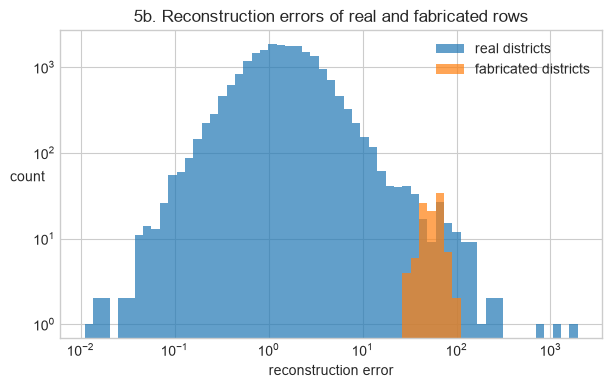

In [45]:
print("5b. Reconstruction error")
errors = reconstruction_errors(D_delivery, pca_components)

print(f"\tError of row {report_row_5}: {errors[report_row_5]}")
print(f"\tMean error of the fabricated rows: {errors[is_corrupted].mean()}")
print(f"\tMean error of the real rows:       {errors[~is_corrupted].mean()}")

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.geomspace(max(errors.min(), 1e-3), errors.max(), 60)
ax.hist(errors[~is_corrupted], bins=bins, alpha=0.7, label="real districts")
ax.hist(errors[is_corrupted], bins=bins, alpha=0.7, label="fabricated districts")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("reconstruction error"); ax.set_ylabel("count", rotation=0)
ax.set_title("5b. Reconstruction errors of real and fabricated rows")
ax.legend()
plt.show()

### 5c. Choosing a threshold

Now we need a rule that decides which rows are fabricated.
The standard rule flags every row whose error is at or above a threshold, and the threshold is often set at a percentile of the error distribution.

__Task:__ Implement `flags_at_percentile`.
For each percentile in `q_percentiles_5c`, the setup code uses your function and counts:

- the __true positives__ $TP$: fabricated rows that were flagged,
- the __false positives__ $FP$: real rows that were flagged.

Write $TP$ and $FP$ for all three percentiles to ANS.


In [46]:
# config
q_percentiles_5c = [90, 95, 99]

In [47]:
# example of how to compute the 75th percentile
np.percentile(errors, 75)

np.float64(2.6204606344579435)

In [48]:
# TODO: flag every row whose error is at or above the given percentile of `errors`.

def flags_at_percentile(errors: np.ndarray, percentile: float) -> np.ndarray:
    # Returns a boolean array, True where the row is flagged.
    #pass # Implement here (use np.percentile)
    threshold = np.percentile(errors, percentile)
    return errors >= threshold

In [49]:
print("5c. Choosing a threshold")
print(f"\t{'percentile':>10} {'threshold':>12} {'flagged':>8} {'TP':>5} {'FP':>6}")
for percentile in q_percentiles_5c:
    flagged = flags_at_percentile(errors, percentile)
    tp = int(np.sum(flagged & is_corrupted))
    fp = int(np.sum(flagged & ~is_corrupted))
    print(f"\t{percentile:>10} {np.percentile(errors, percentile):>12.4f} "
          f"{flagged.sum():>8} {tp:>5} {fp:>6}")

5c. Choosing a threshold
	percentile    threshold  flagged    TP     FP
	        90       4.6349     2046   100   1946
	        95       7.1940     1023   100    923
	        99      38.6466      205    92    113


### 5d. Raising the threshold

__Statement.__ Raising the percentile (say from 90 to 99) can never increase the number of false positives.

__Answer:__ ☐ True ☐ False

True

## 6. k-means clustering

The goal of __k-means clustering__ is to group data into $r$ clusters, without being told what those clusters are.

For this exercise we will again use the California housing dataset. 
The goal is to cluster similar housing districts together and push dissimilar clusters farther apart.

Each cluster is represented by its __centroid__, a point in feature space.
Each data point belongs to the centroid nearest to it.
We stack the $r$ centroids as the columns of $X \in \mathbb{R}^{d \times r}$, and we encode the memberships as $Y \in \mathbb{1}^{n \times r}$, the set of matrices in $\{0, 1\}^{n \times r}$ with exactly one 1 per row. We call $Y$ a __one-hot__ assignment matrix.
A one-hot row times $X^\top$ selects one centroid such that row $i$ of $YX^\top$ is the centroid assigned to district $i$.

The objective

$$RSS(X, Y) = \sum_{i=1}^{n} \| D_{i\cdot} - X_{\cdot s_i}^\top \|^2 = \| D - YX^\top \|^2,$$

where $s_i$ is the cluster of district $i$, is the squared distance between the data and its low-rank approximation.

We again use block coordinate descent to implement the clustering through two steps:

1. __Fix the centroids and solve the assignments.__ Each district is assigned to its nearest centroid. 
2. __Fix the assignments and solve the centroids.__ Each centroid moves to the mean of its districts.

We repeat these two steps until the RSS stops improving. In addition the RSS should never _increase_ when the steps are performed. Since there are only finitely many assignments the loop always stops. This alternation is known as __Lloyd's algorithm__.

### The initialization problem

The starting position of the centroids matters.
Lloyd's algorithm only improves the RSS, so it cannot leave a local optimum. A bad start leads to a bad clustering.

A common solution is to use __greedy k-means++__.
We define the squared distance from a point $\mathbf{v}$ to the nearest centroid in $X$ as

$$\text{dist}(\mathbf{v}, X) = \min_{s} \|\mathbf{v} - X_{\cdot s}\|^2$$

Greedy k-means++ spreads the starting centroids out.
Candidates are sampled with probability proportional to $\text{dist}$, and the candidate that lowers the objective most is kept.

$$
\begin{array}{l}
\textbf{function } \text{InitGreedyKMeans}(D, r, l): \\
\hspace{1em} \text{1. sample } l \text{ candidate rows } i_1, \ldots, i_l \text{ uniformly at random} \\
\hspace{1em} \text{2. } i \leftarrow \arg\min_{i \in \{i_1, \ldots, i_l\}} \sum_{j=1}^n \|D_{j\cdot} - D_{i\cdot}\|^2 \\
\hspace{1em} \text{3. } X \leftarrow [\,D_{i\cdot}^\top\,] \\
\hspace{1em} \text{4. } \textbf{for } s \in \{2, \ldots, r\}: \\
\hspace{3em} \text{a. sample } l \text{ candidates with } p(i) \propto \text{dist}(D_{i\cdot}^\top, X) \\
\hspace{3em} \text{b. } i \leftarrow \arg\min_{i \in \{i_1, \ldots, i_l\}} \sum_{j=1}^n \text{dist}(D_{j\cdot}^\top, [X,\, D_{i\cdot}^\top]) \\
\hspace{3em} \text{c. } X \leftarrow [X,\, D_{i\cdot}^\top] \\
\hspace{1em} \text{5. } \textbf{return } X
\end{array}
$$

Line 2 picks, among the candidates, the row that would best solve the 1-means problem.
Line 4b tries each candidate as a provisional extra centroid and keeps the one that lowers the total distance most.

In [50]:
q_r_6 = 5

# The districts, described by standardized latitude and longitude.
location_raw = pandas_data[["Latitude", "Longitude"]].to_numpy()
location_mean, location_std = location_raw.mean(axis=0), location_raw.std(axis=0)
D_location = (location_raw - location_mean) / location_std

# A deliberately bad starting position for 6b, all five centroids in one spot.
# One centroid per column, as in the book: X has shape (features, r).
bad_init_6b = np.array([
    [-2.00, -2.00],
    [-2.05, -2.00],
    [-2.00, -2.05],
    [-2.05, -2.05],
    [-2.10, -2.00],
]).T


def plot_clusters(D_std, labels, X_std, title):
    # Undo the standardization so the plot reads as a map of California.
    points = D_std * location_std + location_mean
    centroids = X_std.T * location_std + location_mean  # one centroid per row, for plotting
    fig, ax = plt.subplots(figsize=(6.5, 7))
    for cluster in range(len(centroids)):
        in_cluster = labels == cluster
        ax.scatter(points[in_cluster, 1], points[in_cluster, 0], s=4, alpha=0.4,
                   label=f"cluster {cluster} ({in_cluster.sum()} districts)")
    ax.scatter(centroids[:, 1], centroids[:, 0], marker="X", s=180, color="black",
               edgecolor="white", linewidth=1.2, zorder=5, label="centroids")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8, markerscale=2)
    return ax

### 6a. Understanding the initialization

__Question.__ Consider the pseudocode above, with $\text{dist}$ as defined there. One of the following statements is incorrect. Which one?

- __A.__ For a centroid matrix $X$, $\sum_{i=1}^n \text{dist}(D_{i\cdot}^\top, X)$ equals $\min_{Y \in \mathbb{1}^{n \times r}} \|D - YX^\top\|^2$ over one-hot assignment matrices $Y$: the sum of distances-to-nearest is exactly the k-means RSS at those centroids.
- __B.__ The selection in line 4b is equivalent to picking the candidate with the largest sampling probability, $i \leftarrow \arg\max_i p(i)$.
- __C.__ A data point is more likely to be sampled as a candidate the farther it is from all centroids chosen so far.
- __D.__ Line 2 picks the candidate that minimizes the 1-means objective $\|D - \mathbf{1}D_{i\cdot}\|^2$, where $\mathbf{1}$ is the all-ones column vector.

__Answer:__ ☐ A ☐ B ☐ C ☐ D

B

### 6b. Lloyd's algorithm

__Task:__ Implement the following Python functions:

1. `assign_clusters` returns the index of the nearest centroid for every district. This is step 1 in the algorithm.
2. `update_centroids` moves each centroid to the mean of its districts, which is step 2. A centroid whose cluster is empty keeps its old position.
3. `rss` computes the objective.

The setup code runs Lloyd's algorithm from the bad frozen initialization.
Write the RSS at convergence and the number of empty clusters to ANS, and inspect the map.

In [51]:
# TODO: Implement the two exact block updates and the objective.

def assign_clusters(D: np.ndarray, X: np.ndarray) -> np.ndarray:
    # For every row of D, the index of the nearest column of X (squared distance).
    #pass # Implement here
    
    differences = D[:, :, None] - X[None, :, :]
    distances = np.sum(differences ** 2, axis=1)
    return np.argmin(distances, axis=1)


def update_centroids(D: np.ndarray, labels: np.ndarray, X_old: np.ndarray) -> np.ndarray:
    X = X_old.copy()  # a centroid with no districts keeps its old position
    #pass # Implement here

    for cluster in range(X.shape[1]):
        in_cluster = labels == cluster
        if np.any(in_cluster):
            X[:, cluster] = D[in_cluster].mean(axis=0)

    return X

def rss(D: np.ndarray, X: np.ndarray, labels: np.ndarray) -> float:
    #pass # Implement here
    
    assigned_centroids = X[:, labels].T
    return float(np.sum((D - assigned_centroids) ** 2))

In [52]:
# Lloyd's algorithm. Alternate the two exact updates until the RSS stops improving.
def kmeans(D: np.ndarray, X_init: np.ndarray, epsilon: float = 1e-5,
           t_max: int = 1000) -> tuple:
    X = X_init.copy()
    labels = assign_clusters(D, X)
    rss_old = rss(D, X, labels) + 2 * epsilon
    steps = 0
    while rss_old - rss(D, X, labels) > epsilon and steps < t_max:
        rss_old = rss(D, X, labels)
        X = update_centroids(D, labels, X)
        labels = assign_clusters(D, X)
        steps += 1
    return X, labels, rss(D, X, labels), steps

6b. Lloyd's algorithm from a bad start
	RSS at convergence: 6240.809071745303
	Converged after 8 update rounds
	Cluster sizes: [11959     0  8681     0     0]
	Empty clusters: 3


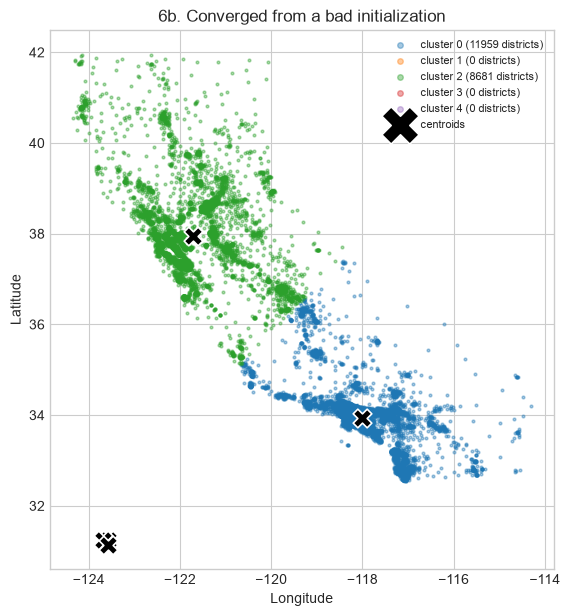

In [53]:
print("6b. Lloyd's algorithm from a bad start")
X_bad, labels_bad, rss_bad, steps_bad = kmeans(D_location, bad_init_6b)
sizes_bad = np.bincount(labels_bad, minlength=q_r_6)
print(f"\tRSS at convergence: {rss_bad}")
print(f"\tConverged after {steps_bad} update rounds")
print(f"\tCluster sizes: {sizes_bad}")
print(f"\tEmpty clusters: {int(np.sum(sizes_bad == 0))}")

plot_clusters(D_location, labels_bad, X_bad, "6b. Converged from a bad initialization")
plt.show()

### 6c. Greedy k-means++

In this exercise you implement greedy k-means++ initialization.
Lines 1 and 4a of the pseudocode sample candidates at random, which would make answers differ between students.
The sampling has therefore been done once for you and frozen.
`q_candidate_rounds_6c` holds the $l = 10$ sampled candidate rows for each of the rounds you need.
You implement the deterministic part of the algorithm: the distance function and the greedy selection of lines 2 and 4b.

__Task:__

1. Implement `dist_to_nearest`, which returns the vector of $\text{dist}(D_{j\cdot}^\top, X)$ for all $j$.
2. Implement `init_greedy_kmeans_pp`. For the first round, pick the candidate minimizing the total squared distance to all districts. For every later round, pick the candidate that minimizes the summed `dist_to_nearest` after provisionally adding it. Stack the winners into the initial centroid matrix.
3. Run the setup code, which runs Lloyd's algorithm from your initialization and draws the map.

Write the RSS at convergence and the size of the largest cluster to ANS.

In [54]:
# The frozen candidate rows, 10 per round. Sampled once with a fixed seed.
q_candidate_rounds_6c = [
    [6307, 18056, 19845, 13383, 4107, 15710, 18862, 8267, 4400, 8448],
    [4519, 1734, 12880, 14428, 12258, 6575, 12221, 14626, 6582, 17719],
    [8775, 5415, 7427, 11863, 14709, 5165, 15380, 11187, 10386, 6486],
    [17346, 1859, 19806, 9689, 17760, 13922, 11833, 19779, 18830, 11729],
    [12384, 17495, 13775, 18815, 17482, 17494, 15216, 13928, 10559, 18174],
]

In [55]:
# TODO: Implement the distance function and the greedy selection.

def dist_to_nearest(D: np.ndarray, X: np.ndarray) -> np.ndarray:
    # For every row of D, the squared distance to the nearest column of X.
    #pass # Implement here
    
    differences = D[:, :, None] - X[None, :, :]
    distances = np.sum(differences ** 2, axis=1)
    return np.min(distances, axis=1)


def init_greedy_kmeans_pp(D: np.ndarray, candidate_rounds: list) -> np.ndarray:
    # Round 1 picks the candidate closest to all rows, later rounds the candidate
    # that minimizes the summed dist_to_nearest. Returns a (features, r) matrix.
    #pass # Implement here
    
    X = np.empty((D.shape[1], 0))

    for candidates in candidate_rounds:
        scores = []

        for row_index in candidates:
            candidate = D[row_index][:, None]
            trial_centroids = np.column_stack((X, candidate))
            score = np.sum(dist_to_nearest(D, trial_centroids))
            scores.append(score)

        best_position = np.argmin(scores)
        best_row = candidates[best_position]
        X = np.column_stack((X, D[best_row]))

    return X

6c. Greedy k-means++
	RSS of the initialization itself: 3153.725826616008
	RSS at convergence: 2435.5538128856424
	Converged after 15 update rounds
	Cluster sizes: [1798 6816 8843  969 2214] (largest: 8843)

	For comparison, the 6b run converged at RSS 6240.809071745303


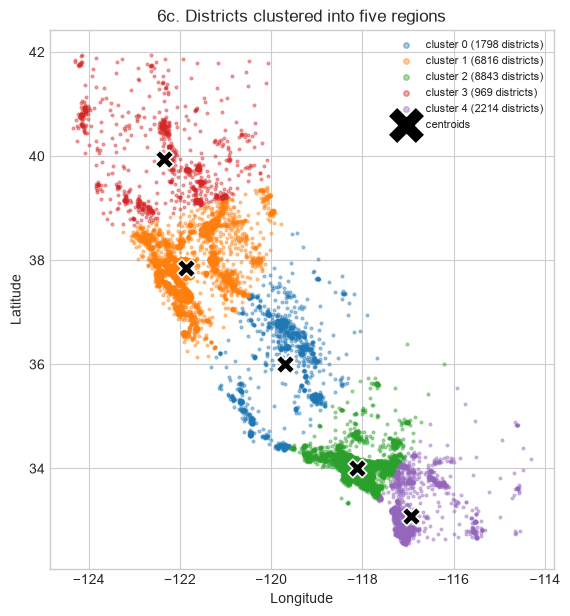

In [56]:
print("6c. Greedy k-means++")
X_init_pp = init_greedy_kmeans_pp(D_location, q_candidate_rounds_6c)
X_pp, labels_pp, rss_pp, steps_pp = kmeans(D_location, X_init_pp)
sizes_pp = np.bincount(labels_pp, minlength=q_r_6)

print(f"\tRSS of the initialization itself: {rss(D_location, X_init_pp, assign_clusters(D_location, X_init_pp))}")
print(f"\tRSS at convergence: {rss_pp}")
print(f"\tConverged after {steps_pp} update rounds")
print(f"\tCluster sizes: {sizes_pp} (largest: {sizes_pp.max()})")
print(f"\n\tFor comparison, the 6b run converged at RSS {rss_bad}")

plot_clusters(D_location, labels_pp, X_pp, "6c. Districts clustered into five regions")
plt.show()

### 6d. Comparing the two initializations

__Statement.__ Starting from the k-means++ initialization, Lloyd's algorithm converged to a lower RSS than it reached from the initialization of 6b.

__Answer:__ ☐ True ☐ False

True